# The automatic junction against hand-drawn regions

The samples picked for annotation (`picks_*.csv`, drawn from the prescreen by *Pick from table*) had their junction drawn by hand in the viewer; each was stored as **`manual annotated junction region`**, with the line it was drawn from. Here the automatic junction finder (`microscopy_viewer/junction.py`) is run on the same samples — the junction only, nothing written into the files — and compared with them.

**What is compared.** A band is a region, so the usual overlap scores apply; but a band is mostly *area*, and a junction that is wrong by 100 µm still overlaps a 300 µm band a lot. So the line itself is measured too.

| Metric | What it says | Good |
|---|---|---|
| **Dice**, band | 2 \|A ∩ M\| / (\|A\| + \|M\|), automatic band A against manual band M, each as its pipeline made it | 1 |
| **IoU**, band | \|A ∩ M\| / \|A ∪ M\| (= Dice / (2 − Dice)) | 1 |
| **Dice, line only** | the automatic band rebuilt *on the organoid the annotator chose*, so only where the line is counts, not which side the band went | 1 |
| **Side agrees** | both bands are on the same organoid | yes |
| **Mean distance** | mean symmetric distance between the two lines, µm (each point of either line to the nearest point of the other) | 0 |
| **HD95** | 95th percentile of those distances, µm: how far the worst stretch is | 0 |
| **Within 50 / 100 µm** | share of the hand-drawn line within 50 / 100 µm of the automatic one | 100 % |

Everything is measured on the overview grid the finder works on (5 µm per pixel), inside the tissue plus the margin. The automatic band is made with the hand-drawn region's own band width, gap and margin, so the two are comparable.

**Variants.** Several settings of the finder's costs are run side by side, from the same overview:

- `bend_um` — what a sharp 90° turn costs (*Bending cost*): 0 is the minimum cut alone.
- `tear_price` — a tear (a hole in the tissue, or stain all but gone) priced like plain tissue (1) instead of being the cheapest thing to cut along (0).
- `edge_weight` — extra price for cutting where the labelled cells do not change: 0 where the density is halfway between the two organoids' levels, up to the weight where it is at either.

Everything else is the finder's default.

The results are cached next to the data (`junction_eval/`), so reopening the notebook does not rerun the finder; set `RECOMPUTE = True` to run it again (a few minutes). **Run All** from the top.

> **21 October 2026:** `028-027_s20` is excluded from every section (organoids separated: there is no junction to find). Prose conclusions dated earlier quote 31 samples; the tables are on 30.

In [1]:
from pathlib import Path
import ssl
import sys
import time

# Some Python installations on Windows cannot read the Windows certificate store; nothing
# here uses the network, but reading an image imports a library that builds an SSL context.
try:
    ssl.create_default_context()
except ssl.SSLError:
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy.spatial import cKDTree

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "microscopy_viewer").is_dir())
sys.path.insert(0, str(ROOT))

from microscopy_viewer import fusion as fu
from microscopy_viewer import ims_store
from microscopy_viewer import junction as jn
from microscopy_viewer import loaders

PICKS = Path(r"D:\Slidescanner extracted\picks_20261020_0742.csv")
OUT = PICKS.parent / "junction_eval"
OUT.mkdir(exist_ok=True)
RECOMPUTE = False

# Each variant: the settings that differ from the finder's defaults.
VARIANTS = {
    "min cut only": dict(bend_um=0.0, tear_price=0.0, edge_weight=0.0),
    "bend 400": dict(bend_um=400.0, tear_price=0.0, edge_weight=0.0),
    "bend 1000": dict(bend_um=1000.0, tear_price=0.0, edge_weight=0.0),
    "bend 1000 + tears": dict(bend_um=1000.0, tear_price=1.0, edge_weight=0.0),
    "bend 1000 + edge 0.5": dict(bend_um=1000.0, tear_price=0.0, edge_weight=0.5),
    "bend 1000 + edge 1": dict(bend_um=1000.0, tear_price=0.0, edge_weight=1.0),
    "bend 1000 + tears + edge 0.5": dict(bend_um=1000.0, tear_price=1.0, edge_weight=0.5),
}
# The variant the pictures show (magenta), and the one drawn dashed beside it.
DEFAULT = "bend 1000"
COMPARE = "min cut only"
print("the finder's own defaults now:", {k: getattr(jn.JunctionOptions(), k) for k in ("bend_um", "tear_price", "edge_weight")})

plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 10})

the finder's own defaults now: {'bend_um': 1000.0, 'tear_price': 0.0, 'edge_weight': 0.0}


## The samples

Every pick that carries a hand-drawn region. The categories come from the prescreen and are used below to see *where* the finder fails.

In [2]:
picks = pd.read_csv(PICKS, encoding="utf-8-sig")
picks["name"] = [Path(p).name.replace(".ome.tiff", "") for p in picks["path"]]
picks["manual"] = [fu.MANUAL_KEY in ims_store.list_labels(p) for p in picks["path"]]
samples_all = picks[picks["manual"]].reset_index(drop=True)
sys.path.insert(0, str(ROOT / "notebooks" / "validation"))
import junction_tuning as jt

# Left out of everything below (junction_tuning.EXCLUDE), with the reason.
samples = samples_all[~samples_all["name"].isin(jt.EXCLUDE)].reset_index(drop=True)
for name, why in jt.EXCLUDE.items():
    print(f"excluded: {name}: {why}")
print(f"{len(picks)} picks, {len(samples)} with a hand-drawn region; without one: "
      + (", ".join(picks.loc[~picks['manual'], 'name']) or "none"))
CATEGORIES = [c for c in ("Ripped", "Folded", "Quality", "Shape") if c in samples.columns]
samples[["name", *CATEGORIES]].value_counts(CATEGORIES).rename("samples").to_frame()

excluded: 2025_09_26_Asssembloid_028-027_s20: organoids separated: no junction to find
37 picks, 30 with a hand-drawn region; without one: 2025_09_26_Asssembloid_023-022_s14, 2025_09_26_Asssembloid_030-029_s7, 2025_09_26_Asssembloid_028-027_s12, 2025_09_26_Asssembloid_029-028_s17, 2025_09_26_Asssembloid_023-022_s5, 2025_09_26_Asssembloid_037-036_s22


samples
Ripped Folded Quality  Shape              
no     yes    Good     Fused pair        5
              Moderate Fused pair        4
yes    yes    Moderate Fused pair        4
no     no     Good     Fused pair        3
yes    yes    Good     Fused pair        2
no     yes    Bad      Fused pair        2
       no     Moderate Fused pair        1
              Good     Damaged           1
       yes    Bad      Damaged           1
       no     Bad      Fused pair        1
yes    no     Bad      Damaged           1
              Good     Damaged           1
              Moderate Fused pair        1
              Good     Fused pair        1
       yes    Bad      Fused pair        1
                       Damaged           1

## Running the finder and scoring it

For each sample: the overview is built once; the hand-drawn region is taken onto the same grid (`[::step, ::step]`, as the overview itself is); the finder runs once per variant; the scores above are computed. The DAPI overview, the hand-drawn band and line, and every variant's band and line are kept in `junction_eval/<sample>.npz`, which is what the pictures below are drawn from. It reruns by itself when the list of variants changes.

In [3]:
def dice(a, b):
    total = a.sum() + b.sum()
    return 2.0 * (a & b).sum() / total if total else np.nan


def iou(a, b):
    union = (a | b).sum()
    return (a & b).sum() / union if union else np.nan


def dense(line_um, step_um=2.0):
    # A polyline resampled every few µm, so distances are to the line, not to its clicks.
    line = np.asarray(line_um, dtype=float)
    pieces = [np.linspace(a, b, max(2, int(np.ceil(np.hypot(*(b - a)) / step_um)) + 1)) for a, b in zip(line[:-1], line[1:])]
    return np.vstack(pieces)


def on_tissue(points_um, region, um):
    # Only the stretch of a line over the tissue (plus margin) is compared: a hand-drawn line
    # often runs on past the outline, and the automatic one stops at it.
    rc = np.round(points_um / um).astype(int)
    ok = (rc[:, 0] >= 0) & (rc[:, 1] >= 0) & (rc[:, 0] < region.shape[0]) & (rc[:, 1] < region.shape[1])
    keep = np.zeros(len(points_um), bool)
    keep[ok] = region[rc[ok, 0], rc[ok, 1]]
    return points_um[keep]


def line_scores(manual_um, auto_um, region, um):
    m = on_tissue(dense(manual_um), region, um)
    a = on_tissue(dense(auto_um), region, um)
    if len(m) < 2 or len(a) < 2:
        return dict(mean_dist=np.nan, hd95=np.nan, within50=np.nan, within100=np.nan)
    d_ma = cKDTree(a).query(m)[0]
    d_am = cKDTree(m).query(a)[0]
    both = np.concatenate([d_ma, d_am])
    return dict(mean_dist=float(both.mean()), hd95=float(np.percentile(both, 95)),
                within50=float((d_ma <= 50).mean()), within100=float((d_ma <= 100).mean()))


def band_on_side(result, overview, options, manual_band):
    # The automatic line, with its band put on the organoid the annotator chose.
    if result.halves is None or result.line_um is None:
        return None
    in_two = (manual_band & (result.halves == 2)).sum() >= (manual_band & (result.halves == 1)).sum()
    copy = jn.JunctionResult(tissue=result.tissue, filled=result.filled, density=result.density,
                             halves=result.halves, line_um=result.line_um)
    jn._build_band(copy, overview, jn.JunctionOptions(**{**options.__dict__, "into_unlabelled": bool(in_two)}))
    return copy.band


def keep_arrays(name, overview, manual_band, manual_line, results):
    # What the pictures need, per sample: so any variant can be drawn without rerunning.
    arrays = {"stain": overview.channels[overview.nuclear].astype(np.float16), "um": overview.um,
              "manual_band": manual_band, "manual_line": manual_line}
    for k, (variant, result) in enumerate(results.items()):
        if result.band is not None and result.line_um is not None:
            arrays[f"band_{k}"], arrays[f"line_{k}"] = result.band, result.line_um
    np.savez_compressed(OUT / f"{name}.npz", **arrays)


def draw(ax, name, variant, compare=None):
    data = np.load(OUT / f"{name}.npz")
    um, stain = float(data["um"]), data["stain"].astype(np.float32)
    ax.imshow(stain, cmap="gray", vmax=np.percentile(stain[stain > 0], 99.5))
    ax.contour(data["manual_band"], [0.5], colors="lime", linewidths=1.2)
    ax.plot(data["manual_line"][:, 1] / um, data["manual_line"][:, 0] / um, color="lime", lw=2)
    for which, colour, style in ((variant, "magenta", "-"), (compare, "orange", "--")):
        if which is None:
            continue
        k = list(VARIANTS).index(which)
        if f"line_{k}" in data:
            if style == "-":
                ax.contour(data[f"band_{k}"], [0.5], colors=colour, linewidths=1.2)
            ax.plot(data[f"line_{k}"][:, 1] / um, data[f"line_{k}"][:, 0] / um, color=colour,
                    lw=2 if style == "-" else 1.2, ls=style)
    ax.set_axis_off()


def evaluate(row):
    path = Path(row["path"])
    labels, attrs = ims_store.load_labels(path, fu.MANUAL_KEY)
    manual_line = np.asarray(attrs["line_yx_um"], dtype=float).reshape(-1, 2)
    number = lambda key, default: float(ims_store._text(attrs[key])) if key in attrs else default
    base = jn.JunctionOptions(save=False, width_um=number("band_width_um", fu.DEFAULT_WIDTH_UM),
                              gap_um=number("start_gap_um", fu.DEFAULT_GAP_UM),
                              margin_um=number("past_tissue_edge_um", fu.TISSUE_MARGIN_UM))
    specs = loaders.load_path(path)
    try:
        started = time.perf_counter()
        overview = jn.build_overview(specs, base)
        read_s = time.perf_counter() - started
    finally:
        loaders.release(path)
    um, step = overview.um, overview.step
    shape = overview.channels.shape[1:]
    manual_band = (np.asarray(labels)[::step, ::step] > 0)[: shape[0], : shape[1]]
    out, results = [], {}
    for variant, settings in VARIANTS.items():
        options = jn.JunctionOptions(**{**base.__dict__, **settings})
        started = time.perf_counter()
        result = jn.find_junction(overview, options)
        took = time.perf_counter() - started
        results[variant] = result
        region = ndimage.binary_dilation(result.filled, iterations=max(1, int(np.ceil(base.margin_um / um))))
        scores = dict(name=row["name"], variant=variant, status=result.status, flags="; ".join(result.flags),
                      seconds=took, read_seconds=read_s)
        if result.band is None or result.line_um is None:
            out.append({**scores, "found": False})
            continue
        auto_band = result.band & region
        manual_in = manual_band & region
        sided = band_on_side(result, overview, options, manual_in)
        in_two = (manual_in & (result.halves == 2)).sum() >= (manual_in & (result.halves == 1)).sum()
        out.append({**scores, "found": True,
                    "dice": dice(auto_band, manual_in), "iou": iou(auto_band, manual_in),
                    "dice_line_only": dice(sided & region, manual_in) if sided is not None else np.nan,
                    "side_agrees": bool(in_two) == bool(options.into_unlabelled),
                    **line_scores(manual_line, result.line_um, region, um)})
    keep_arrays(row["name"], overview, manual_band, manual_line, results)
    return out


cache = OUT / "scores.csv"
stale = not cache.exists() or not set(VARIANTS) <= set(pd.read_csv(cache)["variant"])
if RECOMPUTE or stale:
    rows = []
    for k, row in samples.iterrows():
        started = time.perf_counter()
        try:
            rows.extend(evaluate(row))
            print(f"{k + 1:2d}/{len(samples)} {row['name']}: {time.perf_counter() - started:.0f} s", flush=True)
        except Exception as exc:
            print(f"{k + 1:2d}/{len(samples)} {row['name']}: FAILED {exc}", flush=True)
            rows.extend({"name": row["name"], "variant": v, "found": False, "flags": f"error: {exc}"} for v in VARIANTS)
    pd.DataFrame(rows).to_csv(cache, index=False)
scores = pd.read_csv(cache).merge(samples[["name", *CATEGORIES]], on="name", how="inner")
print(f"{scores['name'].nunique()} samples × {scores['variant'].nunique()} variants, from {cache}")

30 samples × 7 variants, from D:\Slidescanner extracted\junction_eval\scores.csv


## Overall

Median and interquartile range per variant, over the samples where a junction was found; *found* counts those. Lower is better for the distances.

In [4]:
METRICS = {"dice": "Dice", "iou": "IoU", "dice_line_only": "Dice, line only", "mean_dist": "mean distance (µm)",
           "hd95": "HD95 (µm)", "within50": "within 50 µm", "within100": "within 100 µm"}


def summary(frame):
    rows = {}
    for variant, part in frame.groupby("variant", sort=False):
        found = part[part["found"] == True]
        row = {"found": f"{len(found)}/{len(part)}", "side agrees": f"{int(found['side_agrees'].sum())}/{len(found)}"}
        for key, label in METRICS.items():
            q1, med, q3 = np.nanpercentile(found[key], (25, 50, 75)) if len(found) else (np.nan,) * 3
            row[label] = f"{med:.2f} ({q1:.2f}–{q3:.2f})" if key not in ("mean_dist", "hd95") else f"{med:.0f} ({q1:.0f}–{q3:.0f})"
        rows[variant] = row
    return pd.DataFrame(rows).T


summary(scores)

,found,side agrees,Dice,IoU,"Dice, line only",mean distance (µm),HD95 (µm),within 50 µm,within 100 µm
min cut only,26/30,24/26,0.79 (0.57–0.90),0.66 (0.40–0.82),0.79 (0.59–0.90),49 (26–150),124 (97–456),0.68 (0.26–0.86),0.86 (0.46–0.94)
bend 400,26/30,24/26,0.86 (0.70–0.91),0.76 (0.54–0.84),0.88 (0.73–0.91),32 (24–80),101 (65–157),0.74 (0.27–0.88),0.91 (0.66–1.00)
bend 1000,26/30,25/26,0.86 (0.73–0.93),0.76 (0.57–0.87),0.88 (0.74–0.93),30 (18–83),93 (43–156),0.78 (0.48–0.96),0.95 (0.74–1.00)
bend 1000 + tears,26/30,25/26,0.86 (0.77–0.93),0.76 (0.62–0.87),0.86 (0.77–0.93),32 (18–81),102 (44–183),0.74 (0.35–0.95),0.91 (0.76–1.00)
bend 1000 + edge 0.5,26/30,24/26,0.83 (0.70–0.91),0.71 (0.54–0.83),0.83 (0.70–0.91),49 (24–85),113 (72–223),0.66 (0.23–0.87),0.89 (0.64–1.00)
bend 1000 + edge 1,26/30,21/26,0.68 (0.14–0.89),0.52 (0.08–0.79),0.68 (0.46–0.89),86 (28–378),197 (81–474),0.31 (0.02–0.82),0.58 (0.04–0.99)
bend 1000 + tears + edge 0.5,26/30,21/26,0.77 (0.48–0.93),0.63 (0.33–0.86),0.79 (0.68–0.93),59 (21–164),117 (63–361),0.57 (0.12–0.89),0.85 (0.26–1.00)


bend 400                       vs min cut only: closer to the hand-drawn line on  5, further on  6, within 10 µm on 15 of 26
bend 1000                      vs min cut only: closer to the hand-drawn line on 10, further on  5, within 10 µm on 11 of 26
bend 1000 + tears              vs min cut only: closer to the hand-drawn line on  8, further on  5, within 10 µm on 13 of 26
bend 1000 + edge 0.5           vs min cut only: closer to the hand-drawn line on  8, further on  8, within 10 µm on 10 of 26
bend 1000 + edge 1             vs min cut only: closer to the hand-drawn line on  4, further on 13, within 10 µm on  9 of 26
bend 1000 + tears + edge 0.5   vs min cut only: closer to the hand-drawn line on 10, further on 10, within 10 µm on  6 of 26


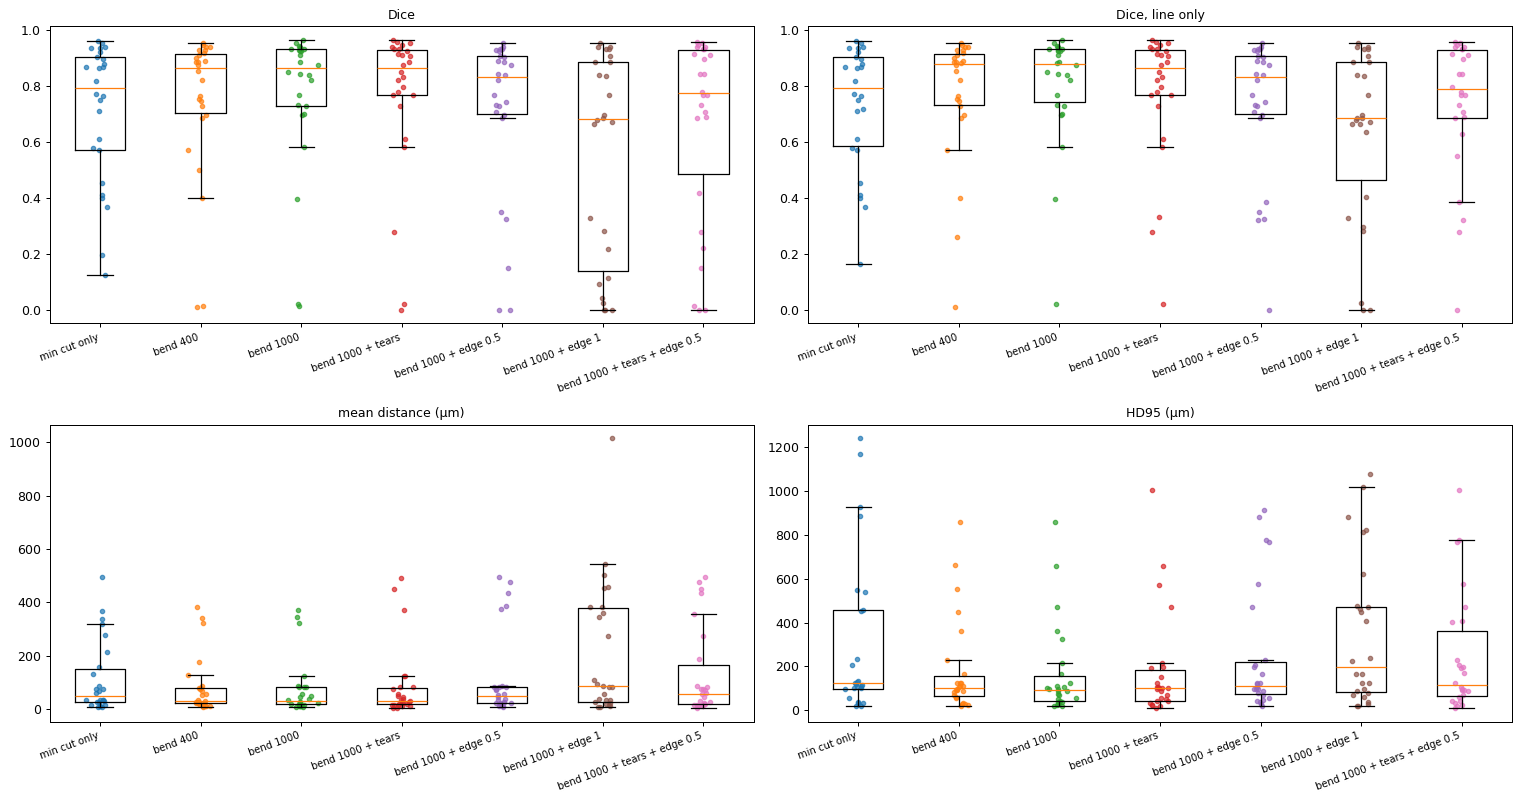

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(17, 9))
axes = axes.ravel()
order = list(VARIANTS)
for ax, key in zip(axes, ("dice", "dice_line_only", "mean_dist", "hd95")):
    data = [scores.loc[(scores["variant"] == v) & (scores["found"] == True), key].dropna() for v in order]
    ax.boxplot(data, showfliers=False)
    for i, values in enumerate(data, start=1):
        ax.scatter(np.random.default_rng(i).normal(i, 0.05, len(values)), values, s=12, alpha=0.7)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=20, ha="right", fontsize=8)
    ax.set_title(METRICS[key])
plt.tight_layout()

# The same sample under the default and the minimum cut alone: who gained, who lost.
wide = scores[scores["found"] == True].pivot(index="name", columns="variant", values="mean_dist")
for variant in VARIANTS:
    if variant == COMPARE or variant not in wide.columns:
        continue
    change = (wide[variant] - wide[COMPARE]).dropna()
    print(f"{variant:30s} vs {COMPARE}: closer to the hand-drawn line on {int((change < -10).sum()):2d}, "
          f"further on {int((change > 10).sum()):2d}, within 10 µm on {int((change.abs() <= 10).sum()):2d} of {len(change)}")

## By category

The default variant, split by the prescreen's categories: does it fail on ripped sections, folded ones, bad ones?

In [6]:
default = scores[(scores["variant"] == DEFAULT)]
tables = []
for category in CATEGORIES:
    for value, part in default.groupby(category):
        found = part[part["found"] == True]
        tables.append({"category": category, "value": value, "samples": len(part), "found": len(found),
                       "Dice": found["dice"].median(), "Dice, line only": found["dice_line_only"].median(),
                       "mean distance (µm)": found["mean_dist"].median(), "within 100 µm": found["within100"].median(),
                       "side agrees": f"{int(found['side_agrees'].sum())}/{len(found)}"})
pd.DataFrame(tables).set_index(["category", "value"]).round(2)

samples  found  Dice  Dice, line only  \
category value                                               
Ripped   no               18     17  0.88             0.88   
         yes              12      9  0.84             0.84   
Folded   no               10      9  0.91             0.91   
         yes              20     17  0.85             0.88   
Quality  Bad               7      5  0.70             0.84   
         Good             13     11  0.93             0.93   
         Moderate         10     10  0.89             0.89   
Shape    Damaged           5      3  0.02             0.58   
         Fused pair       25     23  0.88             0.88   

                     mean distance (µm)  within 100 µm side agrees  
category value                                                      
Ripped   no                       26.23           1.00       16/17  
         yes                      44.34           0.91         9/9  
Folded   no                       25.77           0.97         9/9  
         yes                      34.39           0.94       16/17  
Quality  Bad                      83.71           0.62         4/5  
         Good                     20.57           0.94       11/11  
         Moderate                 25.28           0.99       10/10  
Shape    Damaged                 323.74           0.00         2/3  
         Fused pair               25.77           0.97       23/23

## Per sample

Sorted from the worst mean distance. *Status* and *flags* are the finder's own verdict: a good QC flags the bad ones.

In [7]:
table = default[["name", *CATEGORIES, "status", "flags", "dice", "dice_line_only", "side_agrees", "mean_dist", "hd95", "within100"]]
table = table.sort_values("mean_dist", ascending=False, na_position="first").reset_index(drop=True)
print("finder's status vs how far off it is (median mean distance, µm):",
      table.groupby("status")["mean_dist"].median().round(0).to_dict())
table.round(2)

finder's status vs how far off it is (median mean distance, µm): {'check': 26.0, 'fail': nan, 'ok': 34.0}


,name,Ripped,Folded,Quality,Shape,status,flags,dice,dice_line_only,side_agrees,mean_dist,hd95,within100
0,2025_09_26_Asssembloid_052-051_s14,no,yes,Good,Fused pair,fail,cut off by the scan edge; no junction found,NaN,NaN,NaN,NaN,NaN,NaN
1,2025_09_26_Asssembloid_044-043_s19,yes,yes,Bad,Damaged,fail,organoids not fused; no junction found,NaN,NaN,NaN,NaN,NaN,NaN
2,2025_09_26_Asssembloid_045-044_s16,yes,no,Good,Damaged,fail,no junction found,NaN,NaN,NaN,NaN,NaN,NaN
3,2025_09_26_Asssembloid_052-051_s23,yes,yes,Bad,Fused pair,fail,organoids not fused; no junction found,NaN,NaN,NaN,NaN,NaN,NaN
4,2025_09_26_Asssembloid_033-032_s12,no,no,Good,Damaged,check,cut off by the scan edge; labelled cells on bo...,0.02,0.02,True,371.89,659.82,0.00
5,2025_09_26_Asssembloid_034-033_s17,yes,no,Good,Fused pair,ok,NaN,0.39,0.39,True,344.85,860.20,0.30
6,2025_09_26_Asssembloid_041-040_s1,no,yes,Bad,Damaged,check,labelled cells on both sides (junction uncertain),0.01,0.88,False,323.74,364.22,0.00
7,2025_09_26_Asssembloid_037-036_s25,yes,no,Bad,Damaged,check,labelled cells on both sides (junction uncertain),0.58,0.58,True,124.34,217.64,0.36
8,2025_09_26_Asssembloid_039-038_s5,no,yes,Good,Fused pair,ok,NaN,0.73,0.73,True,85.50,108.78,0.59
9,2025_09_26_Asssembloid_041-040_s26,yes,yes,Moderate,Fused pair,ok,NaN,0.73,0.73,True,83.94,104.56,0.87


## Pictures: the worst and the best

Green: hand-drawn band and line. Magenta: automatic band and line (the `DEFAULT` variant). Orange dashes: the `COMPARE` variant's line. Then the samples where the variants disagree most, every variant side by side.

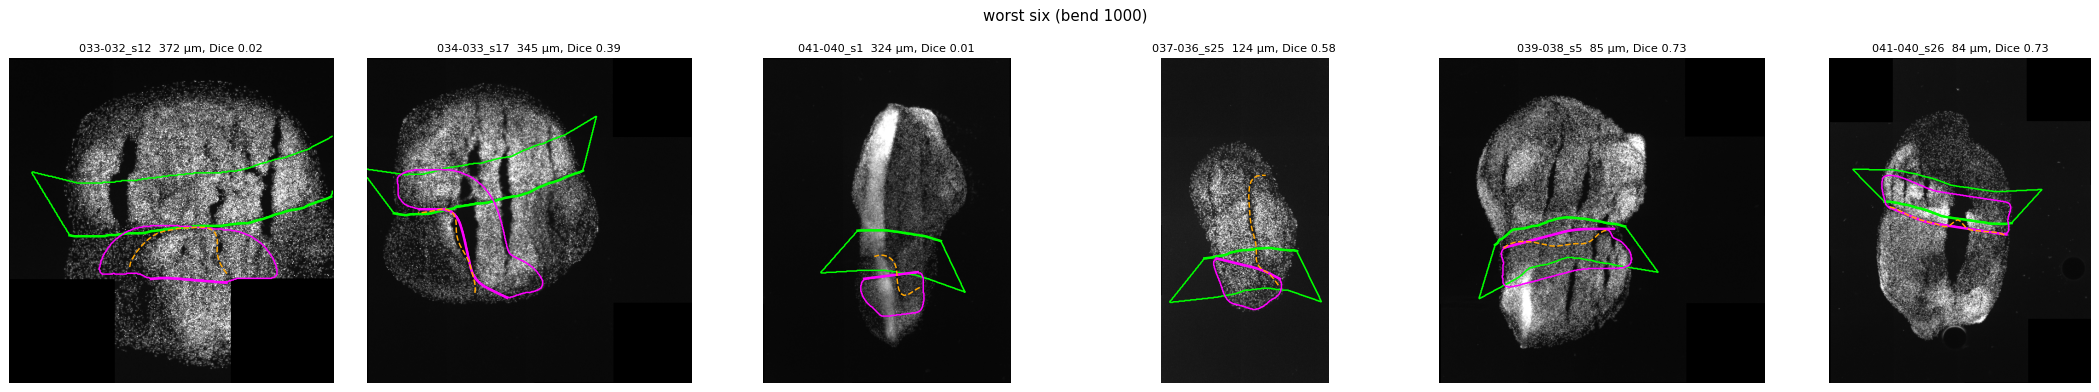

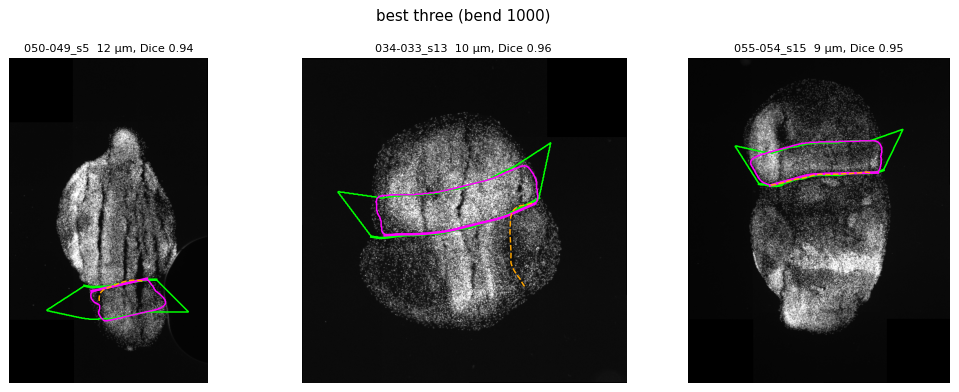

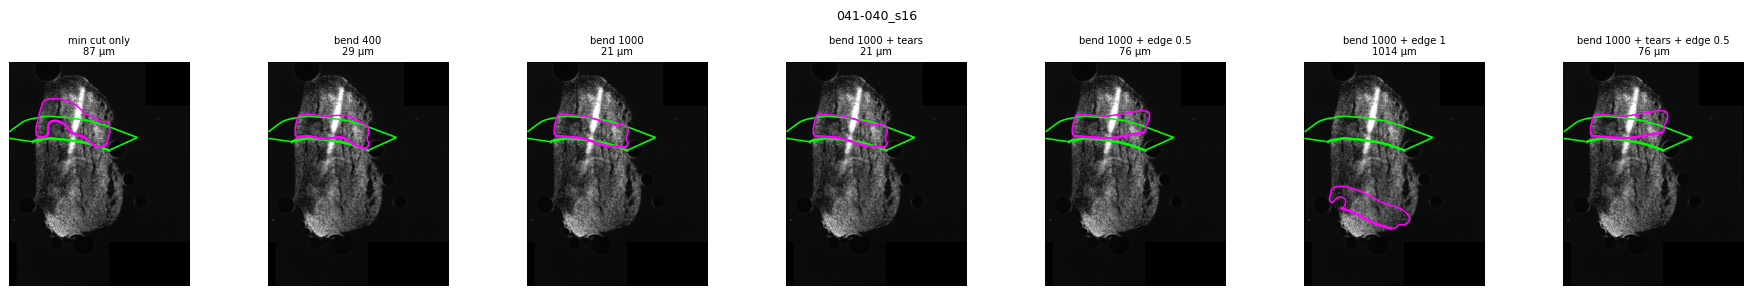

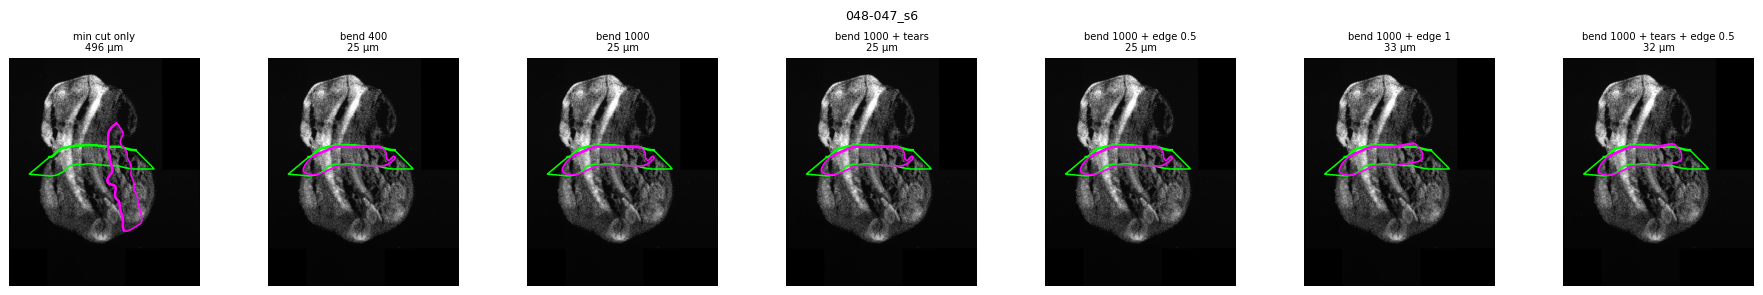

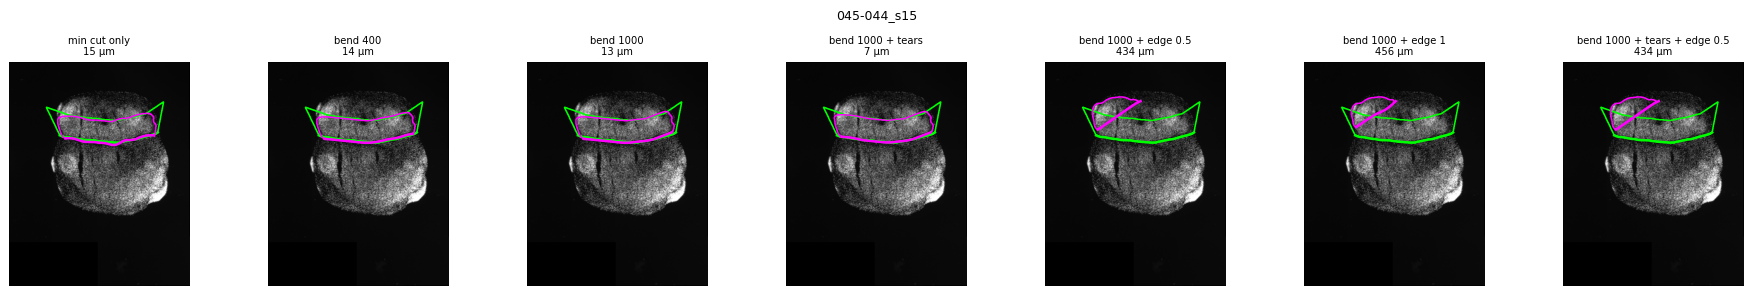

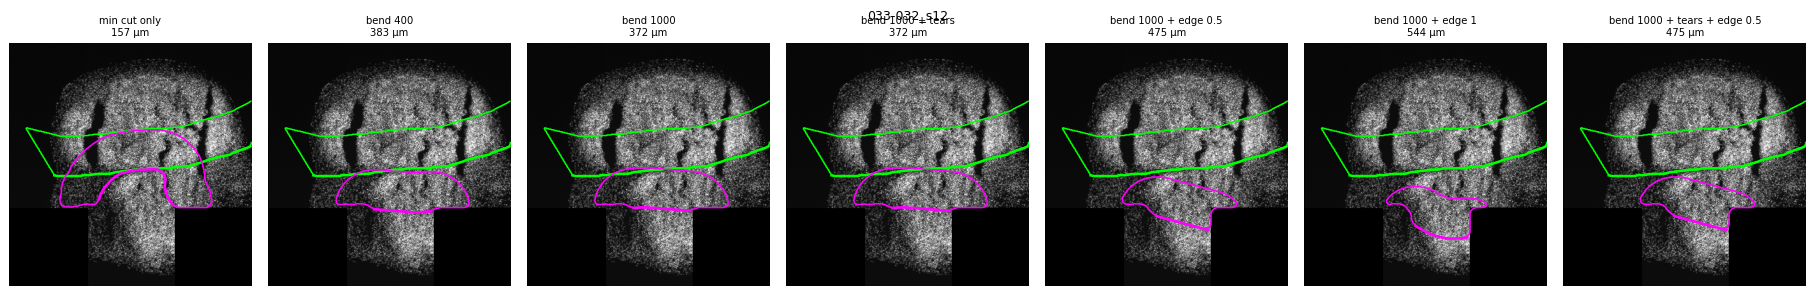

In [8]:
ranked = table.dropna(subset=["mean_dist"])
for title, names in (("worst six", ranked["name"].head(6)), ("best three", ranked["name"].tail(3))):
    names = list(names)
    fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 4.4))
    for ax, name in zip(np.atleast_1d(axes), names):
        draw(ax, name, DEFAULT, COMPARE)
        d = ranked.set_index("name").loc[name]
        ax.set_title(f"{name.split('Asssembloid_')[-1]}  {d['mean_dist']:.0f} µm, Dice {d['dice']:.2f}", fontsize=9)
    fig.suptitle(f"{title} ({DEFAULT})")
    plt.tight_layout()

spread = scores[scores["found"] == True].pivot(index="name", columns="variant", values="mean_dist")
for name in spread.max(axis=1).sub(spread.min(axis=1)).sort_values(ascending=False).index[:4]:
    fig, axes = plt.subplots(1, len(VARIANTS), figsize=(2.9 * len(VARIANTS), 3.3))
    for ax, variant in zip(axes, VARIANTS):
        draw(ax, name, variant)
        ax.set_title(f"{variant}\n{spread.loc[name].get(variant, np.nan):.0f} µm", fontsize=8)
    fig.suptitle(name.split("Asssembloid_")[-1], fontsize=10)
    plt.tight_layout()

## Reading it

Generated from the numbers above when the notebook runs; what was concluded from them (20 October 2026) is under *What was decided*.

In [9]:
s = scores[scores["found"] == True]
med = s.groupby("variant", sort=False)[["dice", "dice_line_only", "mean_dist", "hd95", "within100"]].median()
print(med.round(2).to_string())
best = med["mean_dist"].idxmin()
print(f"\nBest variant by median line distance: {best} ({med.loc[best, 'mean_dist']:.0f} µm; Dice {med.loc[best, 'dice']:.2f}).")
mean = s.groupby("variant", sort=False)[["mean_dist", "hd95"]].mean()
print(f"Best by the mean, which the bad samples weigh in: {mean['mean_dist'].idxmin()} ({mean['mean_dist'].min():.0f} µm).")
d = s[s["variant"] == DEFAULT]
print(f"Default: {int((d['within100'] >= 0.9).sum())} of {len(d)} samples have 90 % of the hand-drawn line within 100 µm; "
      f"{int((d['mean_dist'] > 150).sum())} are off by more than 150 µm on average.")
print(f"Side disagreements (band on the other organoid than the annotator's): {int((~d['side_agrees'].astype(bool)).sum())} of {len(d)}.")
gap = (d["dice_line_only"] - d["dice"]).median()
print(f"Putting the band on the annotator's side changes the median Dice by {gap:+.2f}: "
      + ("the side matters" if abs(gap) > 0.05 else "the side is rarely the problem; the line is"))
for category in CATEGORIES:
    by = d.groupby(category)["mean_dist"].median()
    if len(by) > 1:
        print(f"{category}: median distance " + ", ".join(f"{k} {v:.0f} µm" for k, v in by.items()))

                              dice  dice_line_only  mean_dist    hd95  within100
variant                                                                         
min cut only                  0.79            0.79      48.54  123.57       0.86
bend 400                      0.86            0.88      31.90  101.26       0.91
bend 1000                     0.86            0.88      30.31   92.82       0.95
bend 1000 + tears             0.86            0.86      32.23  102.39       0.91
bend 1000 + edge 0.5          0.83            0.83      48.51  112.60       0.89
bend 1000 + edge 1            0.68            0.68      85.55  196.77       0.58
bend 1000 + tears + edge 0.5  0.77            0.79      58.64  117.14       0.85

Best variant by median line distance: bend 1000 (30 µm; Dice 0.86).
Best by the mean, which the bad samples weigh in: bend 1000 (75 µm).
Default: 16 of 26 samples have 90 % of the hand-drawn line within 100 µm; 3 are off by more than 150 µm on average.
Side disagreement

## What was decided

- **Bending cost 1000 is the default** (it was 400). The median distance to the hand-drawn line is the same (34 µm), but the bad samples come in: HD95 97 µm instead of 106, and 94 % of the hand-drawn line within 100 µm instead of 89 %. Against the minimum cut alone it is closer on 11 samples and further on 5.
- **Pricing tears** (`tear_price=1`) changed little: the same median, a slightly better Dice spread, a slightly worse HD95. It is left off, and in the panel (*Do not cut along tears*) for sections where it helps.
- **Following the labelled cells' edge** (`edge_weight`) made it **worse**, and more so the stronger it is (median distance 53 µm at 0.5, 89 µm at 1). The pictures show why: it pulls the line towards one pole. In these sections the labelled cells' density does not cross halfway at the junction — the label is patchy and has spread — while the annotator places the junction by the tissue's shape and its dark line. Left off.
- **What still fails:** sections the prescreen calls *Damaged* (none usable), and cracks running *from one organoid towards the other*, which the bending cost cannot stop because following them needs no turn. The finder's own status does not predict the error: samples it calls *ok* are as far off as those it calls *check*.

## Tuning the settings: Bayesian optimisation

The settings above were picked by hand, a few at a time. Here six of them are tuned together — only those that shape the line:

| Setting | Range | What it does |
|---|---|---|
| `bend_um` | 100 – 5000 (log) | what a sharp 90° turn costs |
| `tear_price` | 0 – 1.5 | price of cutting along a tear |
| `LINE_POWER` | 2 – 10 | how much cheaper a dark line is than plain tissue |
| `LINE_SMOOTH_UM` | 4 – 20 | blur of the DAPI before the dark line is looked for |
| `LINE_SURROUND_UM` | 30 – 150 | what "darker than its surroundings" is measured against |
| `JUNCTION_SMOOTH_UM` | 50 – 300 | how much the line is smoothed along its length |

**The score** is the mean distance to the hand-drawn line, each sample capped at 300 µm (and a sample with no junction counted as 300): lower is better, and one disaster cannot outweigh everything else.

**The search** (`junction_tuning.py`): the current settings first, then a dozen random ones, then rounds of four proposed by a Gaussian process — a smooth guess of the score over the six settings, with its uncertainty — at the points where it expects the most improvement. Each trial runs the finder on every sample, in parallel, from overviews cached once.

**Overfitting.** With a few dozen samples, a search can find settings that suit *these* samples and no others. So the samples are split once, each category spread over both: about two thirds to **tune** on — the only score the search sees — and a third **held out**. If the best settings are also better on the held-out samples, the gain is real; if only on the tuning ones, it is not.

The search runs outside the notebook (about an hour): `python notebooks/validation/junction_tuning.py --trials 60`. It appends to `junction_eval/trials.jsonl` and can be stopped and resumed.

60 trials; 22 samples to tune on, 8 held out
correlation of tuning and held-out scores over all trials: 0.58


,bend_um,tear_price,LINE_POWER,LINE_SMOOTH_UM,LINE_SURROUND_UM,JUNCTION_SMOOTH_UM,tuning,held out,all
current,1000.00,0.00,6.00,8.00,60.00,150.00,73.30,171.60,99.51
53,685.47,0.59,8.19,5.59,30.00,50.00,64.40,167.86,91.99
44,851.29,0.68,7.54,5.96,30.36,86.94,64.44,166.89,91.76
56,760.55,0.58,9.48,6.04,30.00,50.00,66.32,167.83,93.39
41,853.04,0.28,7.50,5.36,31.93,259.83,66.32,134.56,84.52
25,812.72,0.00,7.11,5.39,30.00,268.19,67.15,170.11,94.61


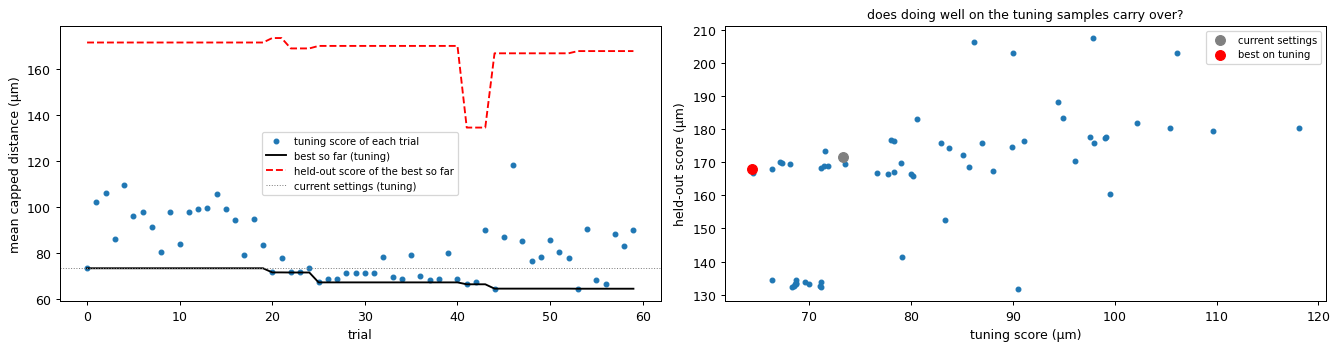

In [10]:
sys.path.insert(0, str(ROOT / "notebooks" / "validation"))
import junction_tuning as jt

trials = jt.load_trials()
# The split is drawn on every annotated sample, then the excluded ones dropped: excluding one moves no other.
tune_names, held_names = jt.split(samples_all)
for t in trials:
    t["rows"] = [r for r in t["rows"] if r["name"] not in jt.EXCLUDE]
print(f"{len(trials)} trials; {len(tune_names)} samples to tune on, {len(held_names)} held out")
assert trials, "no trials yet: run  python notebooks/validation/junction_tuning.py --trials 60"
names_all = list(samples["name"])
frame = pd.DataFrame([{"trial": t["trial"], **t["params"], "tuning": jt.score(t["rows"], tune_names), "held out": jt.score(t["rows"], held_names),
                       "all": jt.score(t["rows"], names_all)} for t in trials])
reference = frame.iloc[0]                       # trial 0: the settings as they are
best_trial = int(frame["tuning"].idxmin())
best = frame.loc[best_trial]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].scatter(frame["trial"], frame["tuning"], s=14, label="tuning score of each trial")
running = frame["tuning"].cummin()
axes[0].plot(frame["trial"], running, "k-", label="best so far (tuning)")
held_of_best = [frame.loc[frame["tuning"].iloc[: k + 1].idxmin(), "held out"] for k in range(len(frame))]
axes[0].plot(frame["trial"], held_of_best, "r--", label="held-out score of the best so far")
axes[0].axhline(reference["tuning"], color="0.5", lw=0.8, ls=":", label="current settings (tuning)")
axes[0].set_xlabel("trial"); axes[0].set_ylabel("mean capped distance (µm)"); axes[0].legend(fontsize=8)
axes[1].scatter(frame["tuning"], frame["held out"], s=14)
axes[1].scatter([reference["tuning"]], [reference["held out"]], c="gray", s=60, label="current settings")
axes[1].scatter([best["tuning"]], [best["held out"]], c="red", s=60, label="best on tuning")
axes[1].set_xlabel("tuning score (µm)"); axes[1].set_ylabel("held-out score (µm)"); axes[1].legend(fontsize=8)
axes[1].set_title("does doing well on the tuning samples carry over?")
plt.tight_layout()
corr = np.corrcoef(frame["tuning"], frame["held out"])[0, 1]
print(f"correlation of tuning and held-out scores over all trials: {corr:.2f}")

columns = [name for name, *_ in jt.PARAMS] + ["tuning", "held out", "all"]
top = frame.sort_values("tuning").head(5)
comparison = pd.concat([reference.to_frame("current").T, top]).loc[:, columns]
comparison.round(2)

held out, best settings vs current, per sample (µm, negative = closer): {'2025_09_26_Asssembloid_019-018_s10': -2.0, '2025_09_26_Asssembloid_026-025_s4': 8.0, '2025_09_26_Asssembloid_033-032_s12': 0.0, '2025_09_26_Asssembloid_034-033_s17': 0.0, '2025_09_26_Asssembloid_044-043_s19': 0.0, '2025_09_26_Asssembloid_045-044_s4': -2.0, '2025_09_26_Asssembloid_052-051_s14': 0.0, '2025_09_26_Asssembloid_055-054_s24': -34.0}
closer on 1, further on 0, within 10 µm on 7 of 8


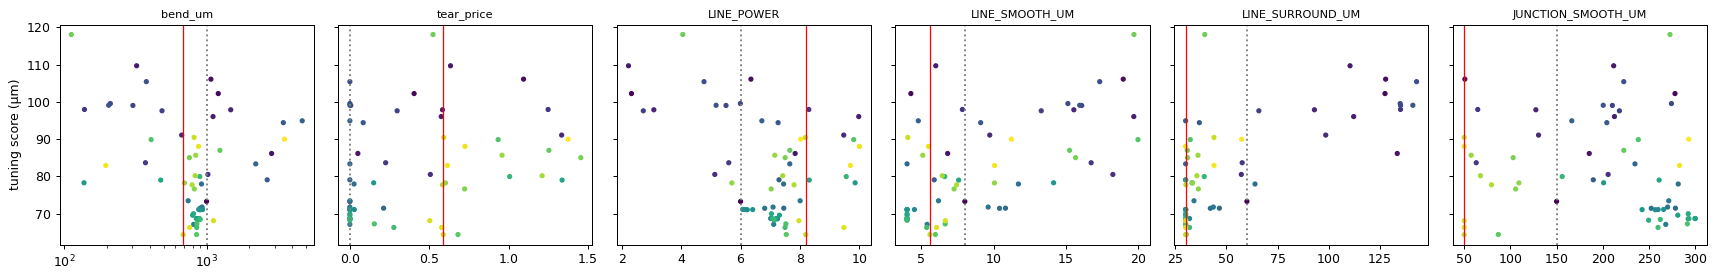

In [11]:
# Each setting against the score: a flat cloud means it hardly matters in this range.
fig, axes = plt.subplots(1, len(jt.PARAMS), figsize=(3.2 * len(jt.PARAMS), 3.2), sharey=True)
for ax, (name, low, high, log) in zip(axes, jt.PARAMS):
    ax.scatter(frame[name], frame["tuning"], s=10, c=frame["trial"], cmap="viridis")
    ax.axvline(reference[name], color="0.5", ls=":")
    ax.axvline(best[name], color="red", lw=1)
    if log:
        ax.set_xscale("log")
    ax.set_title(name, fontsize=9)
axes[0].set_ylabel("tuning score (µm)")
plt.tight_layout()

# Sample by sample, on the held-out samples: the best settings against the current ones.
def per_sample(trial):
    return {r["name"]: jt.capped(r) for r in trials[trial]["rows"]}

now, tuned = per_sample(0), per_sample(best_trial)
held_change = pd.Series({n: tuned[n] - now[n] for n in held_names})
print(f"held out, best settings vs current, per sample (µm, negative = closer): {held_change.round(0).to_dict()}")
print(f"closer on {int((held_change < -10).sum())}, further on {int((held_change > 10).sum())}, "
      f"within 10 µm on {int((held_change.abs() <= 10).sum())} of {len(held_change)}")

## Several candidates, one pick

A different way to use the trials: rather than one setting for every sample, run several and **pick one line per sample** by a rule that does not need the hand-drawn line. Each rule is scored on what it picks.

The candidates are the lines of the ten best trials (by tuning score, which includes the current settings if they are among them). What can be said about a line without knowing the answer:

- **consensus** — the median distance to the other candidates: the line most settings agree on (a *medoid*).
- **darkest** — the mean of the finder's own price along it: the clearest dark junction.
- **smoothest** — how much it bends per mm.
- **shortest** — its length over the tissue.
- **darkest + consensus** — the two ranks added.

Two references: **single best setting** (the best trial, no picking) and **best possible pick** (the candidate closest to the hand-drawn line, which no rule can beat — it shows how much there is to gain by picking at all).

In [12]:
K = 10
pool = frame.sort_values("tuning").head(K)["trial"].astype(int).tolist()
rows_by = {t: {r["name"]: r for r in trials[t]["rows"]} for t in pool}
choices = []
for name in names_all:
    candidates = [(t, rows_by[t][name]) for t in pool if rows_by[t][name].get("found")]
    if not candidates:
        choices.append({"name": name, **{rule: jt.CAP_UM for rule in [*jt.RULES, "single best setting", "best possible pick"]}})
        continue
    lines = [row["line"] for _, row in candidates]
    distances = np.array([jt.capped(row) for _, row in candidates])
    features = jt.line_features(name, lines)
    out = {"name": name}
    for rule in jt.RULES:
        k = jt.pick(features, rule)
        out[rule] = distances[k] if k >= 0 else jt.CAP_UM
    out["single best setting"] = jt.capped(rows_by[pool[0]][name])
    out["best possible pick"] = float(distances.min())
    choices.append(out)
choices = pd.DataFrame(choices).set_index("name")
rules_table = pd.DataFrame({
    "tuning": choices.loc[choices.index.isin(tune_names)].mean(),
    "held out": choices.loc[choices.index.isin(held_names)].mean(),
    "all": choices.mean(),
    "median, all": choices.median(),
}).round(1)
print(f"mean capped distance to the hand-drawn line (µm), picking among the lines of the {K} best trials:")
rules_table.sort_values("all")

mean capped distance to the hand-drawn line (µm), picking among the lines of the 10 best trials:


,tuning,held out,all,"median, all"
best possible pick,60.3,131.2,79.2,22.9
darkest,65.0,131.4,82.7,25.5
smoothest,69.2,135.4,86.9,33.5
single best setting,64.4,167.9,92.0,27.9
consensus,65.6,168.1,92.9,30.3
darkest + consensus,66.9,167.8,93.8,30.3
shortest,67.7,170.5,95.1,33.6


## What the tuning found (20 October 2026, 60 trials)

- **The search improved the tuning samples, not the others.** Its best settings brought the tuning score from 73 to 64 µm, but on the held-out samples it went from 158 to 163 µm — sample by sample, 7 of the 9 held-out lines are unchanged (within 10 µm), one is closer, one further. That is overfitting: with 22 samples to tune on, the search finds what suits those 22. The settings are therefore **left as they are**. (Tuning and held-out scores do move together over all trials, correlation ≈ 0.65, so the search is not blind — there is just little left to gain, and not enough samples to find it reliably.)
- **What the search leaned towards** — a tighter dark-line blur (≈ 5–6 µm instead of 8), a narrower surround (≈ 30 µm instead of 60), a stronger preference for dark lines (power ≈ 7–9 instead of 6), a bending cost a little under 1000, some tear price — is worth trying again once there are more annotated samples, not something to adopt from 22.
- **Picking among candidates helps a little.** Of the rules, *smoothest* (the line bending least, among the ten best trials' lines) did best: 88 µm over all samples against 93 for the single best setting, and better on the held-out ones (135 against 163). *Darkest* and *consensus* did no better than the best setting alone.
- **The ceiling is low.** Even picking the best of the ten candidates for every sample — knowing the answer — only reaches 78 µm overall (23 µm median). Most of what is left comes from a few samples where *no* setting finds the junction (the *Damaged* sections, and those with no junction found, each counted as 300 µm). No tuning of these six settings will reach those.

**So:** the handcrafted finder is close to what it can do on this data. The next gain has to come from a better *price* for cutting — one learned from the hand-drawn lines rather than built from the DAPI by hand (a small network predicting closeness to the junction, used as the cost the cut and the bending already work with) — and from more annotated samples, which both that and any further tuning need. This notebook scores either the same way.

## Does the class of a sample predict how well it works?

The prescreen gives every sample a set of classes (*Ripped*, *Folded*, *Quality*, *Shape*, *Pass*, a cluster, *needs review*), some set by its classifier and some by hand. If the finder's error depends on them, the classes can be used *before* running it: to leave some samples out, or to send them to be drawn by hand. This section asks whether they do, on the `DEFAULT` variant.

**The error measures**, one value per sample, so that samples where no junction was found are counted rather than dropped:

| Measure | Definition | Good |
|---|---|---|
| **error** (primary) | mean distance to the hand-drawn line, capped at 300 µm; *no junction found* counts as 300 µm — the same number the tuning uses (`jt.capped`) | low |
| **Dice** | band overlap as above; *no junction found* counts as 0 | high |
| **not found** | the finder returned no junction | no |
| **fail** | error > 150 µm: the line is somewhere else, or missing | no |
| **side agrees** | the band is on the annotator's organoid (only where a junction was found) | yes |

**How the comparisons are made.** With about 30 samples split into groups of 4–20, differences have to be large to be told from chance, so the tests are chosen to rely on as little as possible:

- the error of the groups is compared by **ranks** — Mann–Whitney for two groups, Kruskal–Wallis for more (with two groups they are the same test) — and the *p*-value comes from **permuting the class labels** 20 000 times instead of from the large-sample approximation, since the groups are small and the error has ties at 300 µm;
- the **effect size** says how large a difference is, whatever *p* says: for two groups **Cliff's δ** — the probability that a sample of the first group has a larger error than one of the second, minus the reverse (−1 to 1; around 0.15 is small, 0.33 medium, 0.47 large); for more groups **ε²** — the share of the variance of the ranks explained by the groups (0 to 1);
- *fail* and *not found* are counts, so they are compared with **Fisher's exact test** (two groups), or the χ² statistic with permuted labels (more groups);
- several classes are tested at once, so some small *p*-values are expected by chance alone. Each measure's *p*-values are therefore corrected over the classes tested, by **Holm** (which controls the chance of *any* false finding) and, more leniently, by **Benjamini–Hochberg** (which controls the expected *share* of false findings, *q*). Only corrected values are called significant, at 0.05.

In [13]:
from scipy import stats

CAP = jt.CAP_UM          # 300 µm, as in the tuning
FAIL_UM = 150.0
CLASS_COLUMNS = ["Ripped", "Folded", "Quality", "Shape", "Pass", "cluster", "needs review"]
CONFIDENT = ["Ripped", "Folded", "Shape", "Pass", "Quality"]       # the classes with a source and a confidence
ORDER = {"Ripped": ["no", "yes"], "Folded": ["no", "yes"], "Quality": ["Good", "Moderate", "Bad"],
         "Shape": ["Fused pair", "Damaged"], "cluster": ["C1", "C2", "C3", "C4", "C5", "C6"]}
MIN_GROUP = 3            # a class value with fewer samples than this is merged or left out (said below)

extra = pd.read_csv(PICKS, encoding="utf-8-sig")
extra["name"] = [Path(p).name.replace(".ome.tiff", "") for p in extra["path"]]
extra_columns = ["name", *CLASS_COLUMNS, *[f"{c} {k}" for c in CONFIDENT for k in ("source", "confidence")]]
cls = (scores.loc[scores["variant"] == DEFAULT, ["name", "status", "flags", "found", "dice", "mean_dist", "side_agrees"]]
       .merge(extra[extra_columns], on="name", how="left").reset_index(drop=True))
cls["found"] = cls["found"].astype(bool)
cls["error"] = np.where(cls["found"], np.minimum(cls["mean_dist"], CAP), CAP)
cls["Dice"] = cls["dice"].where(cls["found"], 0.0)
cls["not found"] = ~cls["found"]
cls["fail"] = cls["error"] > FAIL_UM
cls["flags"] = cls["flags"].fillna("")
assert cls["Ripped"].notna().all(), "a scored sample is missing from the picks table"

# Tiny groups: "review" (the prescreen could not decide) is too rare to stand alone; it is merged with "yes",
# the answer that would send the sample to be checked. Any other value below MIN_GROUP is left out of that test.
for column in ("Ripped", "Folded"):
    cls[column] = cls[column].replace({"review": "yes"})

print(f"{len(cls)} samples with a hand-drawn region, {DEFAULT}; overall: median error {cls['error'].median():.0f} µm, "
      f"mean {cls['error'].mean():.0f} µm, {int(cls['fail'].sum())} fail (> {FAIL_UM:.0f} µm), "
      f"{int(cls['not found'].sum())} of them with no junction found.")
testable = []
for column in CLASS_COLUMNS:
    counts = cls[column].value_counts()
    big = counts[counts >= MIN_GROUP]
    note = "" if len(big) >= 2 else "  -> one value only: nothing to compare, left out"
    if len(big) >= 2:
        testable.append(column)
    small = counts[counts < MIN_GROUP]
    if len(small) and len(big) >= 2:
        note += f"  -> left out of the test: {small.to_dict()}"
    print(f"  {column:13s} {counts.to_dict()}{note}")

30 samples with a hand-drawn region, bend 1000; overall: median error 42 µm, mean 100 µm, 7 fail (> 150 µm), 4 of them with no junction found.
  Ripped        {'no': 18, 'yes': 12}
  Folded        {'yes': 20, 'no': 10}
  Quality       {'Good': 13, 'Moderate': 10, 'Bad': 7}
  Shape         {'Fused pair': 25, 'Damaged': 5}
  Pass          {'yes': 30}  -> one value only: nothing to compare, left out
  cluster       {'C1': 14, 'C2': 7, 'C4': 5, 'C3': 4}
  needs review  {False: 30}  -> one value only: nothing to compare, left out


The picks were not drawn at random from the prescreen: *Pick from table* took a fixed number from each combination of *Ripped*, *Folded* and *Quality* (column `picked for`). That is what makes these comparisons possible at all, but it means the overall error above is the error on this *mix*, not on the whole collection, where good sections are far more common.

### Per class
For each class: the samples per value, the median and interquartile range (25th–75th percentile) of the error, the mean, and the counts; then the tests.

In [14]:
RNG = np.random.default_rng(0)
N_PERM = 20_000


def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


def bh(p):
    p = np.asarray(p, float)
    order = np.argsort(p)[::-1]
    adjusted = np.empty_like(p)
    running = 1.0
    for rank, i in zip(range(len(p), 0, -1), order):
        running = min(running, p[i] * len(p) / rank)
        adjusted[i] = running
    return adjusted


def permuted_labels(labels, n_perm=N_PERM):
    return np.array([RNG.permutation(labels) for _ in range(n_perm)])


def rank_test(values, groups):
    # Kruskal–Wallis H (two groups: two-sided Mann–Whitney); p from permuted labels.
    values, labels = np.asarray(values, float), pd.factorize(np.asarray(groups))[0]
    ranks, k, n = stats.rankdata(values), labels.max() + 1, len(values)
    sizes = np.bincount(labels)

    def h(lab):  # lab: (m, n); the tie correction is a constant, so it does not change the ordering
        sums = np.stack([(ranks * (lab == g)).sum(axis=-1) for g in range(k)], axis=-1)
        return 12.0 / (n * (n + 1)) * (sums ** 2 / sizes).sum(axis=-1) - 3 * (n + 1)

    observed = h(labels[None])[0]
    p = (1 + np.sum(h(permuted_labels(labels)) >= observed - 1e-9)) / (N_PERM + 1)
    if np.ptp(values) == 0:
        return 1.0, 0.0
    H = stats.kruskal(*[values[labels == g] for g in range(k)]).statistic
    return float(p), float(H / (n - 1))          # p, ε²


def cliffs_delta(x, y):
    x, y = np.asarray(x, float)[:, None], np.asarray(y, float)[None, :]
    return float(((x > y).sum() - (x < y).sum()) / (x.size * y.size))


def count_test(flag, groups):
    # Fisher's exact test (two groups), or the χ² statistic with permuted labels (more groups).
    flag, labels = np.asarray(flag, bool), pd.factorize(np.asarray(groups))[0]
    k = labels.max() + 1
    if flag.all() or not flag.any():
        return 1.0
    if k == 2:
        table = [[np.sum(flag & (labels == g)), np.sum(~flag & (labels == g))] for g in range(2)]
        return float(stats.fisher_exact(table).pvalue)
    sizes, total = np.bincount(labels), flag.sum()
    expected = sizes * total / len(flag)

    def chi2(lab):
        hits = np.stack([(flag * (lab == g)).sum(axis=-1) for g in range(k)], axis=-1)
        return (((hits - expected) ** 2) / expected + ((sizes - hits - (sizes - expected)) ** 2) / (sizes - expected)).sum(axis=-1)

    return float((1 + np.sum(chi2(permuted_labels(labels)) >= chi2(labels[None])[0] - 1e-9)) / (N_PERM + 1))


def groups_of(column):
    counts = cls[column].value_counts()
    keep = [v for v in ORDER.get(column, list(counts.index)) if counts.get(v, 0) >= MIN_GROUP]
    return keep, cls[cls[column].isin(keep)]


rows, tests = [], []
for column in testable:
    values, part = groups_of(column)
    for value in values:
        g = part[part[column] == value]
        q1, med, q3 = np.percentile(g["error"], (25, 50, 75))
        found = g[g["found"]]
        rows.append({"class": column, "value": value, "n": len(g), "median error (µm)": round(med),
                     "IQR (µm)": f"{q1:.0f}–{q3:.0f}", "mean error (µm)": round(g["error"].mean()),
                     "median Dice": round(g["Dice"].median(), 2), "fail": f"{int(g['fail'].sum())}/{len(g)}",
                     "not found": f"{int(g['not found'].sum())}/{len(g)}",
                     "side agrees": f"{int(found['side_agrees'].astype(bool).sum())}/{len(found)}"})
    p_err, eps = rank_test(part["error"], part[column])
    p_dice, _ = rank_test(part["Dice"], part[column])
    if len(values) == 2:
        a, b = (part.loc[part[column] == v] for v in values)
        effect = f"δ = {cliffs_delta(b['error'], a['error']):+.2f} ({values[1]} vs {values[0]})"
    else:
        effect = f"ε² = {eps:.2f}"
    tests.append({"class": column, "groups": " / ".join(f"{v} ({(part[column] == v).sum()})" for v in values),
                  "effect on error": effect, "p error": p_err, "p Dice": p_dice,
                  "p fail": count_test(part["fail"], part[column]), "p not found": count_test(part["not found"], part[column])})

by_class = pd.DataFrame(rows).set_index(["class", "value"])
tests = pd.DataFrame(tests).set_index("class")
for measure in ("error", "Dice", "fail", "not found"):
    tests[f"Holm {measure}"] = holm(tests[f"p {measure}"])
    tests[f"BH q {measure}"] = bh(tests[f"p {measure}"])
display(by_class)
tests[["groups", "effect on error", "p error", "Holm error", "BH q error", "p Dice", "Holm Dice",
       "p fail", "Holm fail", "p not found", "Holm not found"]].round(3)

n  median error (µm) IQR (µm)  mean error (µm)  \
class   value                                                         
Ripped  no          18                 30    13–83               78   
        yes         12                 70   26–300              133   
Folded  no          10                 55   12–256              118   
        yes         20                 42    21–84               92   
Quality Good        13                 34   14–300              112   
        Moderate    10                 25    19–53               38   
        Bad          7                124   61–300              168   
Shape   Fused pair  25                 26    18–82               67   
        Damaged      5                300  300–300              265   
cluster C1          14                 19    12–69               81   
        C2           7                 44    32–68               81   
        C3           4                104   71–168              136   
        C4           5                 82   56–300              153   

                    median Dice  fail not found side agrees  
class   value                                                
Ripped  no                 0.87  3/18      1/18       16/17  
        yes                0.71  4/12      3/12         9/9  
Folded  no                 0.80  3/10      1/10         9/9  
        yes                0.84  4/20      3/20       16/17  
Quality Good               0.85  4/13      2/13       11/11  
        Moderate           0.89  0/10      0/10       10/10  
        Bad                0.58   3/7       2/7         4/5  
Shape   Fused pair         0.88  3/25      2/25       23/23  
        Damaged            0.01   4/5       2/5         2/3  
cluster C1                 0.93  3/14      1/14       13/13  
        C2                 0.84   1/7       0/7         6/7  
        C3                 0.64   1/4       1/4         3/3  
        C4                 0.70   2/5       2/5         3/3

,groups,effect on error,p error,Holm error,BH q error,p Dice,Holm Dice,p fail,Holm fail,p not found,Holm not found
class,,,,,,,,,,,
Ripped,no (18) / yes (12),δ = +0.37 (yes vs no),0.091,0.279,0.114,0.069,0.203,0.392,1.000,0.274,0.760
Folded,no (10) / yes (20),δ = +0.07 (yes vs no),0.775,0.775,0.775,0.758,0.758,0.657,1.000,1.000,1.000
Quality,Good (13) / Moderate (10) / Bad (7),ε² = 0.18,0.070,0.279,0.114,0.068,0.203,0.091,0.363,0.242,0.760
Shape,Fused pair (25) / Damaged (5),δ = +0.86 (Damaged vs Fused pair),0.001,0.004,0.004,0.001,0.006,0.006,0.029,0.119,0.594
cluster,C1 (14) / C2 (7) / C3 (4) / C4 (5),ε² = 0.23,0.081,0.279,0.114,0.044,0.176,0.854,1.000,0.190,0.760


Cliff's δ is written *second group against first*: δ = +0.4 for *Shape* means a *Damaged* sample has the larger error in about 40 % more of the pairs than the reverse. The figure shows every sample: the box is the interquartile range with the median, the dashed line the 150 µm *fail* threshold, the top of the axis the 300 µm cap (the open circles: no junction found).

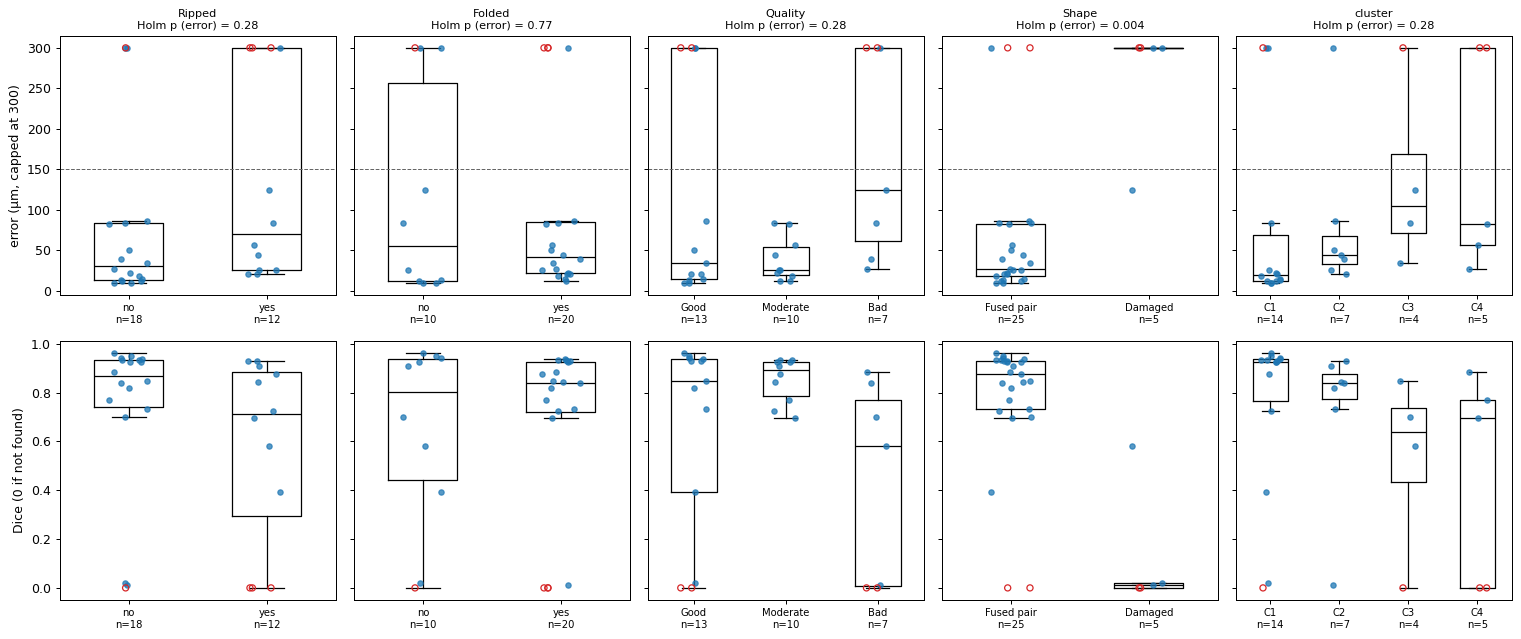

In [15]:
fig, axes = plt.subplots(2, len(testable), figsize=(3.4 * len(testable), 7.2), sharey="row")
for col, column in enumerate(testable):
    values, part = groups_of(column)
    for row, measure in enumerate(("error", "Dice")):
        ax = axes[row, col]
        data = [part.loc[part[column] == v, measure].to_numpy() for v in values]
        ax.boxplot(data, widths=0.5, showfliers=False, medianprops={"color": "black"})
        for i, v in enumerate(values, start=1):
            g = part[part[column] == v]
            x = np.random.default_rng(i).uniform(i - 0.15, i + 0.15, len(g))
            ax.scatter(x[g["found"].to_numpy()], g.loc[g["found"], measure], s=18, color="tab:blue", alpha=0.75, zorder=3)
            ax.scatter(x[~g["found"].to_numpy()], g.loc[~g["found"], measure], s=24, facecolor="none",
                       edgecolor="tab:red", zorder=3)
        ax.set_xticks(range(1, len(values) + 1), [f"{v}\nn={len(d)}" for v, d in zip(values, data)], fontsize=8)
        if row == 0:
            ax.axhline(FAIL_UM, color="0.4", ls="--", lw=0.8)
            holm_p = tests.loc[column, "Holm error"]
            ax.set_title(f"{column}\nHolm p (error) = " + (f"{holm_p:.3f}" if holm_p < 0.01 else f"{holm_p:.2f}"), fontsize=9)
    axes[0, 0].set_ylabel("error (µm, capped at 300)")
    axes[1, 0].set_ylabel("Dice (0 if not found)")
plt.tight_layout()

### Is the prescreen's confidence a warning sign?

The classifier gives each class it sets a **confidence** (the probability it gave its answer). A sample it was unsure about may also be an unusual one, harder for the finder, whatever the answer was. Only samples whose class was set by the classifier have one; those corrected or set by hand (`source` = manual) do not. The **Spearman ρ** is the correlation of the *ranks* of confidence and error (−1 to 1; negative means less confident, larger error); its 95 % interval comes from resampling the samples with replacement (5 000 times), which says how much ρ could move with another set of samples like these.

Then **source** itself: is a class someone had to set by hand a sign of a harder sample?

,n (classifier),ρ with error,95% CI,p,ρ with Dice,p Dice,Holm p,Holm p Dice
confidence of,,,,,,,,
Ripped,12,-0.192,-0.79 to +0.54,0.550,0.312,0.324,0.974,0.536
Folded,29,-0.134,-0.46 to +0.24,0.487,0.213,0.268,0.974,0.536
Shape,26,-0.592,-0.80 to -0.27,0.001,0.589,0.002,0.007,0.008
Pass,19,-0.391,-0.77 to +0.13,0.098,0.427,0.068,0.391,0.273
Quality,27,-0.219,-0.57 to +0.20,0.272,0.294,0.136,0.816,0.408


Shape confidence vs error, classifier 'Fused pair' only: ρ = -0.59 (95% CI -0.81 to -0.23), p = 0.004, n = 22


,manual / classifier,median error manual (µm),median error classifier (µm),δ (manual vs classifier),p,note,Holm p
class,,,,,,,
Ripped,18 / 12,26.0,66.0,-0.16,0.484,NaN,0.802
Folded,1 / 29,NaN,NaN,NaN,NaN,too few set by hand to compare,NaN
Shape,4 / 26,172.0,32.0,0.42,0.201,NaN,0.802
Pass,11 / 19,25.0,56.0,-0.24,0.284,NaN,0.802
Quality,3 / 27,20.0,50.0,-0.43,0.248,NaN,0.802


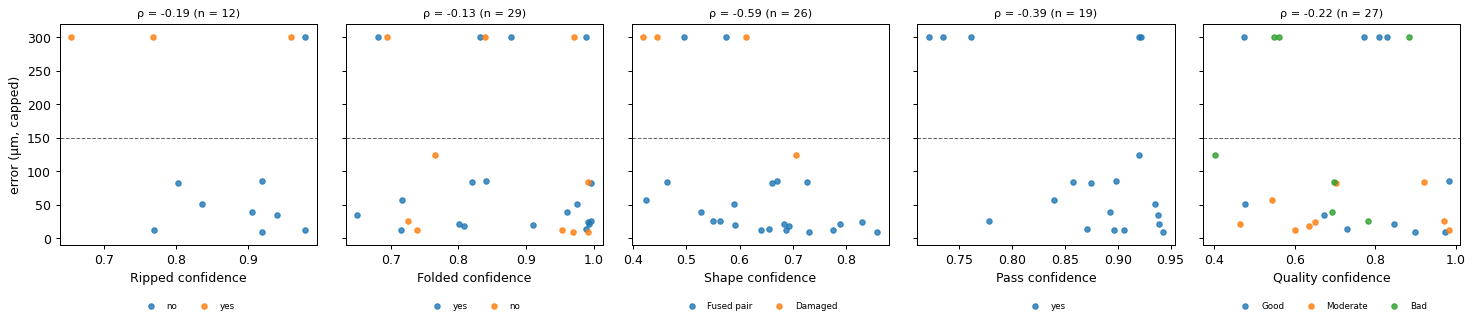

In [16]:
def spearman_ci(x, y, n_boot=5000):
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho, p = stats.spearmanr(x, y)
    draws = RNG.integers(0, len(x), size=(n_boot, len(x)))
    boot = [stats.spearmanr(x[i], y[i])[0] for i in draws if np.ptp(x[i]) > 0 and np.ptp(y[i]) > 0]
    low, high = np.nanpercentile(boot, (2.5, 97.5))
    return rho, p, low, high


conf_rows = []
for column in CONFIDENT:
    part = cls[(cls[f"{column} source"] == "classifier") & cls[f"{column} confidence"].notna()]
    rho, p, low, high = spearman_ci(part[f"{column} confidence"], part["error"])
    rho_d, p_d, *_ = spearman_ci(part[f"{column} confidence"], part["Dice"])
    conf_rows.append({"confidence of": column, "n (classifier)": len(part), "ρ with error": rho,
                      "95% CI": f"{low:+.2f} to {high:+.2f}", "p": p, "ρ with Dice": rho_d, "p Dice": p_d})
conf = pd.DataFrame(conf_rows).set_index("confidence of")
conf["Holm p"] = holm(conf["p"])
conf["Holm p Dice"] = holm(conf["p Dice"])
display(conf.round(3))
# Is the Shape confidence more than a second way of saying "Damaged"? The same correlation within Fused pair alone:
fused = cls[(cls["Shape source"] == "classifier") & (cls["Shape"] == "Fused pair")]
rho, p, low, high = spearman_ci(fused["Shape confidence"], fused["error"])
print(f"Shape confidence vs error, classifier 'Fused pair' only: ρ = {rho:+.2f} (95% CI {low:+.2f} to {high:+.2f}), "
      f"p = {p:.3f}, n = {len(fused)}")

src_rows = []
for column in CONFIDENT:
    source = cls[f"{column} source"]
    counts = source.value_counts()
    if counts.get("manual", 0) < MIN_GROUP or counts.get("classifier", 0) < MIN_GROUP:
        src_rows.append({"class": column, "manual / classifier": f"{counts.get('manual', 0)} / {counts.get('classifier', 0)}",
                         "note": "too few set by hand to compare"})
        continue
    p, _ = rank_test(cls["error"], source)
    m, c = cls.loc[source == "manual", "error"], cls.loc[source == "classifier", "error"]
    src_rows.append({"class": column, "manual / classifier": f"{len(m)} / {len(c)}",
                     "median error manual (µm)": round(m.median()), "median error classifier (µm)": round(c.median()),
                     "δ (manual vs classifier)": round(cliffs_delta(m, c), 2), "p": p})
source_table = pd.DataFrame(src_rows).set_index("class")
tested = source_table["p"].notna()
source_table.loc[tested, "Holm p"] = holm(source_table.loc[tested, "p"])
display(source_table.round(3))

fig, axes = plt.subplots(1, len(CONFIDENT), figsize=(3.3 * len(CONFIDENT), 3.8), sharey=True)
for ax, column in zip(axes, CONFIDENT):
    part = cls[(cls[f"{column} source"] == "classifier") & cls[f"{column} confidence"].notna()]
    for value, colour in zip(part[column].unique(), plt.cm.tab10.colors):
        g = part[part[column] == value]
        ax.scatter(g[f"{column} confidence"], g["error"], s=18, color=colour, label=str(value), alpha=0.8)
    ax.axhline(FAIL_UM, color="0.4", ls="--", lw=0.8)
    ax.set_xlabel(f"{column} confidence")
    ax.set_title(f"ρ = {conf.loc[column, 'ρ with error']:+.2f} (n = {len(part)})", fontsize=9)
    ax.set_ylim(-10, 320)
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
axes[0].set_ylabel("error (µm, capped)")
plt.tight_layout()

### Classes together

The classes are not independent of each other (a ripped section is more often folded or damaged, say), so a difference seen in one may belong to another. Two views: the error in each **Ripped × Folded** cell (the combinations the picks were stratified by), and **Quality × Shape**; then a small **linear regression** of the error on all four classes at once, which estimates each class's difference *with the others held fixed*. With 31 samples and five coefficients this is exploratory: its standard errors are the robust kind (HC3, which does not assume equal scatter in every group, and is conservative in small samples), and it is fitted a second time on the *ranks* of the error, so that the few 300 µm samples cannot drive it alone.

n = 30; R² = 0.49 (error), 0.44 (ranks). Coefficients: difference from a not-ripped, not-folded, Good, Fused-pair sample.


error (µm)                               rank of error             \
          coefficient 95% CI low 95% CI high      p   coefficient 95% CI low   
Intercept      62.904    -13.241     139.050  0.105         9.869      2.701   
ripped         39.989    -56.241     136.219  0.415         4.408     -2.300   
folded         19.943    -63.694     103.580  0.640         3.576     -3.423   
moderate      -60.856   -146.646      24.933  0.164        -2.834    -10.149   
bad             0.580   -119.101     120.261  0.992         2.893     -5.181   
damaged       169.646     41.066     298.226  0.010        10.520      1.595   

                              
          95% CI high      p  
Intercept      17.037  0.007  
ripped         11.115  0.198  
folded         10.575  0.317  
moderate        4.481  0.448  
bad            10.968  0.482  
damaged        19.445  0.021

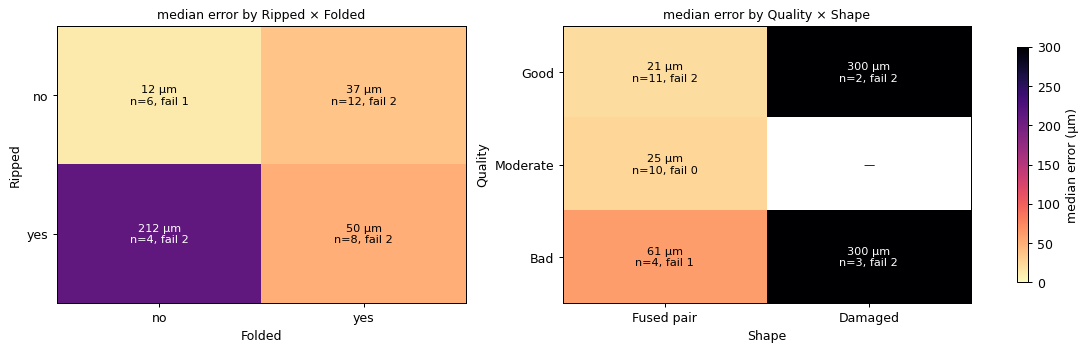

In [17]:
def cell_text(g):
    return f"{g['error'].median():.0f} µm\nn={len(g)}, fail {int(g['fail'].sum())}" if len(g) else "—"


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, (rows_c, cols_c) in zip(axes, (("Ripped", "Folded"), ("Quality", "Shape"))):
    r_vals = [v for v in ORDER[rows_c] if v in set(cls[rows_c])]
    c_vals = [v for v in ORDER[cols_c] if v in set(cls[cols_c])]
    grid = np.full((len(r_vals), len(c_vals)), np.nan)
    for i, rv in enumerate(r_vals):
        for j, cv in enumerate(c_vals):
            g = cls[(cls[rows_c] == rv) & (cls[cols_c] == cv)]
            if len(g):
                grid[i, j] = g["error"].median()
            ax.text(j, i, cell_text(g), ha="center", va="center", fontsize=9,
                    color="white" if np.nan_to_num(grid[i, j]) > 150 else "black")
    im = ax.imshow(grid, cmap="magma_r", vmin=0, vmax=CAP, aspect="auto")
    ax.set_xticks(range(len(c_vals)), c_vals); ax.set_yticks(range(len(r_vals)), r_vals)
    ax.set_xlabel(cols_c); ax.set_ylabel(rows_c)
    ax.set_title(f"median error by {rows_c} × {cols_c}")
fig.colorbar(im, ax=axes, label="median error (µm)", shrink=0.85)

try:
    import statsmodels.formula.api as smf
except ImportError:
    smf = None
design = cls.assign(ripped=(cls["Ripped"] == "yes").astype(int), folded=(cls["Folded"] == "yes").astype(int),
                    moderate=(cls["Quality"] == "Moderate").astype(int), bad=(cls["Quality"] == "Bad").astype(int),
                    damaged=(cls["Shape"] == "Damaged").astype(int), error_rank=stats.rankdata(cls["error"]))
formula_terms = "ripped + folded + moderate + bad + damaged"
if smf is not None:
    fits = {"error (µm)": smf.ols(f"error ~ {formula_terms}", design).fit(cov_type="HC3"),
            "rank of error": smf.ols(f"error_rank ~ {formula_terms}", design).fit(cov_type="HC3")}
    regression = pd.concat({k: pd.DataFrame({"coefficient": f.params, "95% CI low": f.conf_int()[0],
                                             "95% CI high": f.conf_int()[1], "p": f.pvalues}) for k, f in fits.items()}, axis=1)
    print(f"n = {len(design)}; R² = {fits['error (µm)'].rsquared:.2f} (error), {fits['rank of error'].rsquared:.2f} (ranks). "
          "Coefficients: difference from a not-ripped, not-folded, Good, Fused-pair sample.")
    display(regression.round(3))
else:
    print("statsmodels is not installed: regression skipped")

### The finder's own verdict

The finder labels each result *ok*, *check* or *fail* and lists why (flags). *fail* means it found no junction, so its error is 300 µm by definition; the useful question is whether *check* warns of a bad line among the ones it did draw, and whether its verdict follows the prescreen's classes.

In [18]:
found = cls[cls["found"]]
status_table = cls.groupby("status").agg(n=("error", "size"), median_error=("error", "median"), mean_error=("error", "mean"),
                                         fail=("fail", "sum")).round(0)
display(status_table)
ok, check = found.loc[found["status"] == "ok", "error"], found.loc[found["status"] == "check", "error"]
p_status, _ = rank_test(found["error"], found["status"])
print(f"found only: ok n={len(ok)} median {ok.median():.0f} µm, check n={len(check)} median {check.median():.0f} µm; "
      f"δ (check vs ok) = {cliffs_delta(check, ok):+.2f}, permutation p = {p_status:.2f}")

flag_names = sorted({f.strip() for text in cls["flags"] for f in text.split(";") if f.strip()})
flag_rows = []
for flag in flag_names:
    has = cls["flags"].str.contains(flag, regex=False)
    flag_rows.append({"flag": flag, "samples": int(has.sum()), "median error with (µm)": round(cls.loc[has, "error"].median()),
                      "median error without (µm)": round(cls.loc[~has, "error"].median()),
                      "fail with": f"{int(cls.loc[has, 'fail'].sum())}/{int(has.sum())}"})
display(pd.DataFrame(flag_rows).set_index("flag"))

verdict_rows = []
for column in testable:
    values, part = groups_of(column)
    verdict_rows.append({"class": column, "p (status vs class)": count_test(part["status"] != "ok", part[column]),
                         **{f"not ok | {v}": f"{int((part.loc[part[column] == v, 'status'] != 'ok').sum())}/{int((part[column] == v).sum())}"
                            for v in values}})
verdict = pd.DataFrame(verdict_rows).set_index("class")
verdict["Holm p"] = holm(verdict["p (status vs class)"])
verdict.round(3).fillna("")

,n,median_error,mean_error,fail
status,,,,
check,17,26.0,70.0,2
fail,4,300.0,300.0,4
ok,9,34.0,68.0,1


found only: ok n=9 median 34 µm, check n=17 median 26 µm; δ (check vs ok) = -0.05, permutation p = 0.88


,samples,median error with (µm),median error without (µm),fail with
flag,,,,
cut off by the scan edge,2,300,37,2/2
junction very short,2,41,42,0/2
labelled cells on both sides (junction uncertain),15,26,56,2/15
large holes or torn,1,26,44,0/1
no junction found,4,300,30,4/4
organoids not fused,2,300,37,2/2
ragged outline,3,56,39,0/3


,p (status vs class),not ok | no,not ok | yes,not ok | Good,not ok | Moderate,not ok | Bad,not ok | Fused pair,not ok | Damaged,not ok | C1,not ok | C2,not ok | C3,not ok | C4,Holm p
class,,,,,,,,,,,,,
Ripped,1.000,13/18,8/12,,,,,,,,,,1.0
Folded,0.675,8/10,13/20,,,,,,,,,,1.0
Quality,0.537,,,8/13,7/10,6/7,,,,,,,1.0
Shape,0.286,,,,,,16/25,5/5,,,,,1.0
cluster,0.470,,,,,,,,9/14,4/7,3/4,5/5,1.0


### Which samples are sensitive to the settings?

The 60 trials of the tuning ran the finder on every sample with different settings. For each sample, the spread of its error over those trials says how much the settings matter for it: a sample that is right (or wrong) under every setting is not one that tuning can help. Measured as the interquartile range of the error over the 60 trials, and the lowest error any trial reached (*best*). Trial 0 is the current settings; it is checked against the scores above first, since both should be the same run.

trial 0 against the bend 1000 scores: 1 of 30 samples differ by more than 1 µm: 020-019_s4 (26 vs 50 µm)


,median IQR | no,median IQR | yes,p,ε²,median IQR | Good,median IQR | Moderate,median IQR | Bad,median IQR | Fused pair,median IQR | Damaged,median IQR | C1,median IQR | C2,median IQR | C3,median IQR | C4,Holm p
class,,,,,,,,,,,,,,
Ripped,8.0,7.0,0.598,0.01,,,,,,,,,,1.0
Folded,7.0,8.0,0.912,0.00,,,,,,,,,,1.0
Quality,,,0.868,0.01,7.0,10.0,9.0,,,,,,,1.0
Shape,,,0.354,0.03,,,,7.0,0.0,,,,,1.0
cluster,,,0.204,0.16,,,,,,6.0,42.0,9.0,6.0,1.0


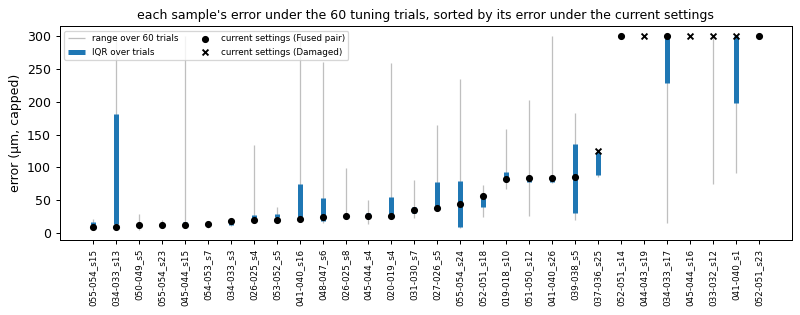

In [19]:
names_cls = list(cls["name"])
E = pd.DataFrame({t["trial"]: {r["name"]: jt.capped(r) for r in t["rows"]} for t in trials}).loc[names_cls]
mismatch = (E[0] - cls.set_index("name")["error"]).abs()
print(f"trial 0 against the {DEFAULT} scores: {int((mismatch > 1).sum())} of {len(mismatch)} samples differ by more than 1 µm"
      + (": " + ", ".join(f"{n.split('Asssembloid_')[-1]} ({E.loc[n, 0]:.0f} vs {cls.set_index('name').loc[n, 'error']:.0f} µm)"
                          for n in mismatch[mismatch > 1].index) if (mismatch > 1).any() else ""))
spread = pd.DataFrame({"IQR over trials": E.quantile(0.75, axis=1) - E.quantile(0.25, axis=1),
                       "best": E.min(axis=1), "current": E[0]})
cls = cls.join(spread, on="name")
sens_rows = []
for column in testable:
    values, part = groups_of(column)
    p, eps = rank_test(part["IQR over trials"], part[column])
    sens_rows.append({"class": column, **{f"median IQR | {v}": round(part.loc[part[column] == v, "IQR over trials"].median())
                                         for v in values}, "p": p, "ε²": round(eps, 2)})
sens = pd.DataFrame(sens_rows).set_index("class")
sens["Holm p"] = holm(sens["p"])
display(sens.round(3).fillna(""))

fig, ax = plt.subplots(figsize=(9, 3.6))
ordered = cls.sort_values("current")
x = np.arange(len(ordered))
lo, hi = E.loc[ordered["name"]].min(axis=1), E.loc[ordered["name"]].max(axis=1)
q1, q3 = E.loc[ordered["name"]].quantile(0.25, axis=1), E.loc[ordered["name"]].quantile(0.75, axis=1)
ax.vlines(x, lo, hi, color="0.75", lw=1, label="range over 60 trials")
ax.vlines(x, q1, q3, color="tab:blue", lw=4, label="IQR over trials")
for value, marker in (("Fused pair", "o"), ("Damaged", "x")):
    sel = (ordered["Shape"] == value).to_numpy()
    ax.scatter(x[sel], ordered["current"].to_numpy()[sel], marker=marker,
               color="black", s=22, zorder=3, label=f"current settings ({value})")
ax.set_xticks(x, [n.split("Asssembloid_")[-1] for n in ordered["name"]], rotation=90, fontsize=7)
ax.set_ylabel("error (µm, capped)"); ax.legend(fontsize=7, ncol=2)
ax.set_title("each sample's error under the 60 tuning trials, sorted by its error under the current settings")
plt.tight_layout()

### Different settings for different classes?

If the classes behaved differently under the settings, each class could get its own settings, chosen from the 60 trials. Whether that helps can be tested with the trials alone, but only **honestly** if a sample's own result is never used to choose the settings it is scored with. So every choice is made **leave-one-out**: for each sample in turn,

- **global** — the trial with the lowest mean error over all *other* samples, scored on the sample left out;
- **per class** — the trial with the lowest mean error over the other samples *of the same class*, scored on it;
- **per class, shrunk** — the trial minimising *(mean error over the other samples of the class) + λ × (mean error over all other samples)*: λ = 0 is plain per class, larger λ pulls the choice towards settings that also work on everything else (a hedge against a class with few samples). λ is 0, 0.5 or 1, and a fourth version picks λ itself, by the same leave-one-out on the other samples only (nested), so that choosing λ cannot leak either;
- **defaults** — trial 0, the current settings (no choice at all);
- **oracle per class** — the best trial for the whole class, *including* the sample scored. This is not a method: it is the optimistic ceiling of what per-class settings could do here if nothing was overfitted.

Groupings with a class of fewer than 5 samples are merged first (say below). The per-sample leave-one-out errors of *per class* and *global* are compared with the **Wilcoxon signed-rank test** (paired, on each sample's difference; ties at zero are kept, Pratt's method).

In [20]:
LAMBDAS = (0.0, 0.5, 1.0)
M = E.to_numpy()                     # samples × trials
n_s = len(M)


def best_trial(rows, weights_rows=None, lam=0.0):
    # Trial minimising the mean over `rows`, plus lam × the mean over `weights_rows`.
    if len(rows) == 0:
        rows = weights_rows
    cost = M[rows].mean(axis=0)
    if lam and weights_rows is not None and len(weights_rows):
        cost = cost + lam * M[weights_rows].mean(axis=0)
    return int(np.argmin(cost))


def loo_errors(groups, lam, members=None):
    # Per-class choice for each sample in `members`, using only the other members.
    members = np.arange(n_s) if members is None else np.asarray(members)
    out = {}
    for s in members:
        others = members[members != s]
        same = others[groups[others] == groups[s]]
        out[s] = M[s, best_trial(same, others, lam)]
    return out


def nested_lambda(groups):
    # λ chosen by leave-one-out on the other samples only, then used for the sample left out.
    out = {}
    everyone = np.arange(n_s)
    for s in everyone:
        others = everyone[everyone != s]
        inner = {lam: np.mean(list(loo_errors(groups, lam, others).values())) for lam in LAMBDAS}
        lam = min(inner, key=inner.get)
        same = others[groups[others] == groups[s]]
        out[s] = (M[s, best_trial(same, others, lam)], lam)
    return out


everyone = np.arange(n_s)
global_loo = np.array([M[s, best_trial(everyone[everyone != s])] for s in everyone])
defaults = M[:, 0]

rf = pd.Series([("ripped" if r == "yes" else "not ripped") + (", folded" if f == "yes" else ", not folded")
                for r, f in zip(cls["Ripped"], cls["Folded"])])
rf = rf.replace({"ripped, not folded": "ripped (folded or not)", "ripped, folded": "ripped (folded or not)"})
GROUPINGS = {"Ripped": cls["Ripped"], "Folded": cls["Folded"], "Quality": cls["Quality"], "Shape": cls["Shape"],
             "Ripped × Folded": rf}
print("Ripped × Folded: 'ripped, not folded' has 4 samples, so it is merged with 'ripped, folded' "
      "(that group is then the same as Ripped = yes).")

summary_rows, per_class_rows, choice_rows = [], [], []
loo_results = {}
for grouping, labels in GROUPINGS.items():
    groups = labels.to_numpy()
    sizes = pd.Series(groups).value_counts()
    variants = {f"per class, λ={lam:g}": np.array([loo_errors(groups, lam)[s] for s in everyone]) for lam in LAMBDAS}
    nested = nested_lambda(groups)
    variants["per class, λ chosen (nested)"] = np.array([nested[s][0] for s in everyone])
    oracle = np.array([M[s, best_trial(np.flatnonzero(groups == groups[s]))] for s in everyone])
    loo_results[grouping] = variants
    lam_used = pd.Series([nested[s][1] for s in everyone]).value_counts().to_dict()
    for name, err in {"defaults (trial 0)": defaults, "global (LOO)": global_loo, **variants, "oracle per class (optimistic)": oracle}.items():
        diff = err - global_loo
        nonzero = np.abs(diff) > 1e-9
        p = stats.wilcoxon(err, global_loo, zero_method="pratt").pvalue if nonzero.any() else np.nan
        same = "identical to global" if not nonzero.any() and name != "global (LOO)" else ""
        summary_rows.append({"grouping": grouping, "method": name, "mean (µm)": err.mean(), "median (µm)": np.median(err),
                             "better than global >10 µm": int((diff < -10).sum()), "worse >10 µm": int((diff > 10).sum()),
                             "Wilcoxon p vs global": p,
                             "note": "; ".join(x for x in (f"λ picked: {lam_used}" if "nested" in name else "", same) if x)})
    best_lam = f"per class, λ={LAMBDAS[0]:g}"
    for value in sizes.index:
        sel = groups == value
        per_class_rows.append({"grouping": grouping, "class": value, "n": int(sel.sum()),
                               "defaults": defaults[sel].mean(), "global (LOO)": global_loo[sel].mean(),
                               "per class λ=0 (LOO)": variants[best_lam][sel].mean(),
                               "per class, nested λ (LOO)": variants["per class, λ chosen (nested)"][sel].mean(),
                               "oracle per class": oracle[sel].mean()})
        t = best_trial(np.flatnonzero(sel))
        choice_rows.append({"grouping": grouping, "class": value, "n": int(sel.sum()), "trial chosen (all data)": t,
                            **{k: v for k, v in trials[t]["params"].items()}, "class mean at it (µm)": M[sel, t].mean(),
                            "class mean at defaults (µm)": M[sel, 0].mean()})

print("Samples whose leave-one-out error changes by more than 10 µm, per class (nested λ) against global:")
for grouping, variants in loo_results.items():
    diff = variants["per class, λ chosen (nested)"] - global_loo
    moved = [f"{names_cls[s].split('Asssembloid_')[-1]} {global_loo[s]:.0f} → {global_loo[s] + diff[s]:.0f} µm"
             for s in np.flatnonzero(np.abs(diff) > 10)]
    print(f"  {grouping:16s} " + ("; ".join(moved) or "none"))

t_global = best_trial(everyone)
choice_rows.append({"grouping": "—", "class": "all samples (global)", "n": n_s, "trial chosen (all data)": t_global,
                    **trials[t_global]["params"], "class mean at it (µm)": M[:, t_global].mean(), "class mean at defaults (µm)": M[:, 0].mean()})
loo_summary = pd.DataFrame(summary_rows).set_index(["grouping", "method"])
print("Mean / median leave-one-out error over all samples (µm), and the paired comparison with one global setting:")
display(loo_summary.round(3))
print("Mean error per class (µm):")
display(pd.DataFrame(per_class_rows).set_index(["grouping", "class"]).round(0))
print("Which trial each class would choose with all its samples (stability and what it changes):")
pd.DataFrame(choice_rows).set_index(["grouping", "class"]).round(2)

Ripped × Folded: 'ripped, not folded' has 4 samples, so it is merged with 'ripped, folded' (that group is then the same as Ripped = yes).


Samples whose leave-one-out error changes by more than 10 µm, per class (nested λ) against global:
  Ripped           034-033_s13 15 → 300 µm; 052-051_s18 39 → 58 µm; 027-026_s5 35 → 81 µm
  Folded           045-044_s15 13 → 300 µm; 027-026_s5 35 → 77 µm
  Quality          052-051_s18 39 → 57 µm; 019-018_s10 93 → 80 µm
  Shape            037-036_s25 89 → 126 µm; 041-040_s1 199 → 248 µm
  Ripped × Folded  034-033_s13 15 → 182 µm; 045-044_s15 13 → 35 µm; 052-051_s18 39 → 58 µm; 019-018_s10 93 → 81 µm; 027-026_s5 35 → 81 µm; 051-050_s12 87 → 50 µm
Mean / median leave-one-out error over all samples (µm), and the paired comparison with one global setting:


mean (µm)  median (µm)  \
grouping        method                                                  
Ripped          defaults (trial 0)                99.513       36.558   
                global (LOO)                      95.726       36.346   
                per class, λ=0                   104.452       66.482   
                per class, λ=0.5                 107.361       65.387   
                per class, λ=1                    96.334       36.346   
                per class, λ chosen (nested)     107.389       65.811   
                oracle per class (optimistic)     83.051       27.271   
Folded          defaults (trial 0)                99.513       36.558   
                global (LOO)                      95.726       36.346   
                per class, λ=0                   102.804       34.472   
                per class, λ=0.5                  97.091       38.496   
                per class, λ=1                    95.814       36.346   
                per class, λ chosen (nested)     106.950       56.275   
                oracle per class (optimistic)     81.694       24.841   
Quality         defaults (trial 0)                99.513       36.558   
                global (LOO)                      95.726       36.346   
                per class, λ=0                    98.276       29.793   
                per class, λ=0.5                  97.079       34.062   
                per class, λ=1                    95.564       36.346   
                per class, λ chosen (nested)      95.564       36.346   
                oracle per class (optimistic)     78.177       27.109   
Shape           defaults (trial 0)                99.513       36.558   
                global (LOO)                      95.726       36.346   
                per class, λ=0                    98.595       36.346   
                per class, λ=0.5                  98.595       36.346   
                per class, λ=1                   100.337       36.346   
                per class, λ chosen (nested)      98.595       36.346   
                oracle per class (optimistic)     77.464       30.188   
Ripped × Folded defaults (trial 0)                99.513       36.558   
                global (LOO)                      95.726       36.346   
                per class, λ=0                    97.718       34.123   
                per class, λ=0.5                 103.448       53.777   
                per class, λ=1                   103.360       53.777   
                per class, λ chosen (nested)     102.251       54.201   
                oracle per class (optimistic)     74.955       28.725   

                                               better than global >10 µm  \
grouping        method                                                     
Ripped          defaults (trial 0)                                     2   
                global (LOO)                                           0   
                per class, λ=0                                         1   
                per class, λ=0.5                                       0   
                per class, λ=1                                         0   
                per class, λ chosen (nested)                           0   
                oracle per class (optimistic)                          4   
Folded          defaults (trial 0)                                     2   
                global (LOO)                                           0   
                per class, λ=0                                         3   
                per class, λ=0.5                                       0   
                per class, λ=1                                         0   
                per class, λ chosen (nested)                           0   
                oracle per class (optimistic)                          4   
Quality         defaults (trial 0)                                     2   
                global (LOO)                         

Mean error per class (µm):


n  defaults  global (LOO)  \
grouping        class                                                
Ripped          no                      18      77.0          75.0   
                yes                     12     133.0         126.0   
Folded          yes                     20      90.0          86.0   
                no                      10     118.0         115.0   
Quality         Good                    13     110.0         112.0   
                Moderate                10      38.0          37.0   
                Bad                      7     168.0         148.0   
Shape           Fused pair              25      66.0          67.0   
                Damaged                  5     265.0         237.0   
Ripped × Folded not ripped, folded      12      80.0          76.0   
                ripped (folded or not)  12     133.0         126.0   
                not ripped, not folded   6      71.0          73.0   

                                        per class λ=0 (LOO)  \
grouping        class                                         
Ripped          no                                     89.0   
                yes                                   128.0   
Folded          yes                                    82.0   
                no                                    144.0   
Quality         Good                                  112.0   
                Moderate                               34.0   
                Bad                                   164.0   
Shape           Fused pair                             67.0   
                Damaged                               255.0   
Ripped × Folded not ripped, folded                     66.0   
                ripped (folded or not)                128.0   
                not ripped, not folded                101.0   

                                        per class, nested λ (LOO)  \
grouping        class                                               
Ripped          no                                           94.0   
                yes                                         128.0   
Folded          yes                                          88.0   
                no                                          144.0   
Quality         Good                                        112.0   
                Moderate                                     37.0   
                Bad                                         148.0   
Shape           Fused pair                                   67.0   
                Damaged                                     255.0   
Ripped × Folded not ripped, folded                           77.0   
                ripped (folded or not)                      128.0   
                not ripped, not folded                      101.0   

                                        oracle per class  
grouping        class                                     
Ripped          no                                  70.0  
                yes                                103.0  
Folded          yes                                 79.0  
                no                                  86.0  
Quality         Good                                86.0  
                Moderate                            28.0  
                Bad                                134.0  
Shape           Fused pair                          54.0  
                Damaged                            195.0  
Ripped × Folded not ripped, folded                  66.0  
                ripped (folded or not)             103.0  
                not ripped, not folded              37.0

Which trial each class would choose with all its samples (stability and what it changes):


n  trial chosen (all data)  bend_um  \
grouping        class                                                          
Ripped          no                      18                       44   851.29   
                yes                     12                       41   853.04   
Folded          yes                     20                       48   820.04   
                no                      10                       28   937.19   
Quality         Good                    13                       41   853.04   
                Moderate                10                       53   685.47   
                Bad                      7                       12   304.07   
Shape           Fused pair              25                       41   853.04   
                Damaged                  5                       13   211.10   
Ripped × Folded not ripped, folded      12                       48   820.04   
                ripped (folded or not)  12                       41   853.04   
                not ripped, not folded   6                        5  1110.51   
—               all samples (global)    30                       41   853.04   

                                        tear_price  LINE_POWER  \
grouping        class                                            
Ripped          no                            0.68        7.54   
                yes                           0.28        7.50   
Folded          yes                           0.72        7.03   
                no                            0.03        6.16   
Quality         Good                          0.28        7.50   
                Moderate                      0.59        8.19   
                Bad                           0.01        5.51   
Shape           Fused pair                    0.28        7.50   
                Damaged                       0.00        5.99   
Ripped × Folded not ripped, folded            0.72        7.03   
                ripped (folded or not)        0.28        7.50   
                not ripped, not folded        0.58        9.98   
—               all samples (global)          0.28        7.50   

                                        LINE_SMOOTH_UM  LINE_SURROUND_UM  \
grouping        class                                                      
Ripped          no                                5.96             30.36   
                yes                               5.36             31.93   
Folded          yes                               7.25             36.23   
                no                                4.51             30.00   
Quality         Good                              5.36             31.93   
                Moderate                          5.59             30.00   
                Bad                              16.09            135.23   
Shape           Fused pair                        5.36             31.93   
                Damaged                          15.13            135.02   
Ripped × Folded not ripped, folded                7.25             36.23   
                ripped (folded or not)            5.36             31.93   
                not ripped, not folded           19.69            112.27   
—               all samples (global)              5.36             31.93   

                                        JUNCTION_SMOOTH_UM  \
grouping        class                                        
Ripped          no                                   86.94   
                yes                                 259.83   
Folded          yes                                 105.72   
                no                                  259.93   
Quality         Good                                259.83   
                Moderate                             50.00   
                Bad                                 210.38   
Shape           Fused pair                          259.83   
                Damaged                             274.34   
Ripped × Folded not ripped

### In practice: which samples to leave out, or draw by hand?

A rule can only use what is known before the finder runs, so each candidate rule below excludes samples by their prescreen classes alone. For each: how many samples it keeps, the error on those, how many *fail*s remain, and the cost — how many of the excluded samples the finder actually got right (error ≤ 50 µm), which would then be drawn by hand for nothing. The last rule adds the finder's own *fail* (no junction found), which is also known without a hand-drawn line. The rules were chosen after looking at the tables above, on the same samples, so the gains are optimistic; they would need confirming on new samples.

In [21]:
RULES = {
    "none (all samples)": pd.Series(False, index=cls.index),
    "Shape = Damaged": cls["Shape"] == "Damaged",
    "Quality = Bad": cls["Quality"] == "Bad",
    "Damaged or Bad": (cls["Shape"] == "Damaged") | (cls["Quality"] == "Bad"),
    "Ripped = yes": cls["Ripped"] == "yes",
    "Damaged or Ripped": (cls["Shape"] == "Damaged") | (cls["Ripped"] == "yes"),
    # Shape set by the classifier with less than even odds (a Shape set by hand has no confidence and is kept)
    "Damaged, or Shape confidence < 0.5": (cls["Shape"] == "Damaged") | (cls["Shape confidence"] < 0.5),
    # Not a prescreen rule: the finder's own "fail" (no junction) is also known without a hand-drawn line.
    "Damaged, or the finder found none": (cls["Shape"] == "Damaged") | ~cls["found"],
}
rule_rows = []
for rule, out in RULES.items():
    kept, gone = cls[~out], cls[out]
    rule_rows.append({"exclude": rule, "kept": len(kept), "excluded": len(gone),
                      "mean error kept (µm)": kept["error"].mean(), "median error kept (µm)": kept["error"].median(),
                      "fail kept": f"{int(kept['fail'].sum())}/{len(kept)}",
                      "fail caught": f"{int(gone['fail'].sum())}/{int(cls['fail'].sum())}",
                      "excluded but fine (≤ 50 µm)": f"{int((gone['error'] <= 50).sum())}/{len(gone)}"})
rules_out = pd.DataFrame(rule_rows).set_index("exclude").round(1)
display(rules_out)
print("The fails, and their classes:")
cls.loc[cls["fail"], ["name", "Ripped", "Folded", "Quality", "Shape", "status", "error", "flags"]].sort_values("error").round(0)

,kept,excluded,mean error kept (µm),median error kept (µm),fail kept,fail caught,excluded but fine (≤ 50 µm)
exclude,,,,,,,
none (all samples),30,0,100.3,41.5,7/30,0/7,0/0
Shape = Damaged,25,5,67.4,26.2,3/25,4/7,0/5
Quality = Bad,23,7,79.9,25.8,4/23,3/7,2/7
Damaged or Bad,21,9,58.9,24.8,2/21,5/7,2/9
Ripped = yes,18,12,78.3,30.3,3/18,4/7,5/12
Damaged or Ripped,16,14,50.6,23.8,1/16,6/7,5/14
"Damaged, or Shape confidence < 0.5",22,8,56.6,25.3,2/22,5/7,0/8
"Damaged, or the finder found none",23,7,47.2,25.8,1/23,6/7,0/7


The fails, and their classes:


,name,Ripped,Folded,Quality,Shape,status,error,flags
5,2025_09_26_Asssembloid_052-051_s14,no,yes,Good,Fused pair,fail,300.0,cut off by the scan edge; no junction found
9,2025_09_26_Asssembloid_034-033_s17,yes,no,Good,Fused pair,ok,300.0,
10,2025_09_26_Asssembloid_044-043_s19,yes,yes,Bad,Damaged,fail,300.0,organoids not fused; no junction found
11,2025_09_26_Asssembloid_045-044_s16,yes,no,Good,Damaged,fail,300.0,no junction found
16,2025_09_26_Asssembloid_033-032_s12,no,no,Good,Damaged,check,300.0,cut off by the scan edge; labelled cells on bo...
26,2025_09_26_Asssembloid_041-040_s1,no,yes,Bad,Damaged,check,300.0,labelled cells on both sides (junction uncertain)
29,2025_09_26_Asssembloid_052-051_s23,yes,yes,Bad,Fused pair,fail,300.0,organoids not fused; no junction found


### What this says (20 October 2026, 31 samples, `bend 1000`)

Overall: median error 44 µm, mean 99 µm; 7 of 31 samples *fail* (error > 150 µm), 4 of them with no junction found. *Pass* (all "yes") and *needs review* (all False) have one value among these samples, so they cannot be tested; no *Ripped* or *Folded* was "review", so nothing had to be merged.

- **Shape is the one class that clearly matters.** The 5 *Damaged* samples have a median error of 300 µm (4 of 5 fail) against 30 µm for the 26 *Fused pair* (3 fail); Cliff's δ = +0.86, Holm-corrected *p* = 0.003 for the error, 0.009 for Dice, 0.025 for *fail*. It holds with the other classes in the regression: *Damaged* adds about 170 µm (95 % CI 41–299 µm; *p* = 0.01, and *p* = 0.02 on ranks). With 5 samples, how much worse is uncertain; *that* it is worse is not.
- **Nothing else is significant after correction.** *Ripped* (12 yes: median 70 µm against 34 µm, δ = +0.36, *p* = 0.10 before and 0.28 after correction), *Quality* (Good 42 / Moderate 25 / Bad 124 µm, n = 14 / 10 / 7, ε² = 0.17, corrected *p* = 0.28), *cluster* (ε² = 0.23, corrected *p* = 0.28) and *Folded* (δ = +0.07, *p* = 0.79). *Ripped* and *Bad* point the expected way and may be real, but these samples cannot show it: the intervals are wide, and *Quality* is not even ordered (Moderate does better than Good, whose fails include two *Damaged*). The 4 *ripped, not folded* samples are the worst cell of Ripped × Folded (median 212 µm), but 4 samples are an anecdote.
- **The prescreen's confidence in Shape is a warning sign; the others are not.** The lower the classifier's Shape confidence, the larger the error: Spearman ρ = −0.56 (95 % CI −0.78 to −0.24, n = 27, Holm *p* = 0.01), and it is not just *Damaged* again — among the *Fused pair* alone ρ = −0.54 (CI −0.78 to −0.18, n = 23). The confidences of Ripped, Folded, Quality and Pass do not correlate with the error after correction, and whether a class was set by hand or by the classifier makes no difference that can be seen (all corrected *p* ≥ 0.86).
- **The finder's own verdict says little beyond *fail*.** *fail* is by definition no junction. Among the junctions drawn, *check* and *ok* are equally good (median 35 and 34 µm, δ = −0.02, *p* = 0.94): the flag behind most *check*s, *labelled cells on both sides*, does not mark worse lines. The status does not follow the prescreen's classes either (all corrected *p* = 1). The one silent failure — 300 µm with status *ok* — is a ripped, unfolded *Fused pair* (`034-033_s17`).
- **No class is more sensitive to the settings than another** (spread of each sample's error over the 60 trials; corrected *p* ≥ 0.5). The *Damaged* samples are wrong under almost every setting: tuning cannot rescue them. Trial 0 matches the scores above on 30 of 31 samples; `020-019_s4` differs (26 µm in the trials, 50 µm here), presumably because the trials run from cached overviews.
- **Different settings per class do not help, tested honestly.** One global setting chosen leave-one-out gives a mean error of 96 µm (median 35 µm; the current defaults 98 / 39 µm). Choosing per class, leave-one-out, is *worse* for Ripped (103 µm), Folded (110 µm) and Ripped × Folded (105 µm; Wilcoxon *p* = 0.03, < 0.001 and 0.002 against global), and no better for Shape (99 µm). Shrinking towards the global choice (λ picked by nested leave-one-out) mostly just returns the global setting; where it does better (Quality and Folded, 87 µm), the whole gain is one sample (`034-033_s17`, 300 → 16 µm), *p* ≥ 0.3. The per-class choices that look interpretable — a much lower bending cost (≈ 200–300) with heavier smoothing for *Bad* and for *Damaged*, a little tear price for *Ripped* — rest on 7 and 5 samples and are not confirmed when held out. The optimistic ceiling (best trial per class, the samples included) is 76–83 µm, which shows there is something to gain in principle, but 4–26 samples per class are too few to find it reliably. **So: one setting for all**; applying classes in batch through the prescreen table (971 samples, every one classified) is not worth it with these trials.

**In practice.** Send **Shape = *Damaged*** to be drawn by hand: here that catches 4 of the 7 fails and none of the samples the finder got right; the remaining 26 have a mean error of 67 µm (median 30 µm) instead of 99 (44). Adding the samples where the finder itself finds no junction leaves 24 samples, mean 48 µm, median 26 µm, with one silent fail; adding instead a Shape confidence below 0.5 leaves 23, mean 57 µm, again without losing a good one. Leaving out *Ripped* or *Bad* would cost good results (5 of 12 and 2 of 7 excluded samples were within 50 µm) for less gain. These rules were chosen on the same 31 samples, so their numbers are optimistic; and the finder has not been tried at all on *Separated* or *Empty / debris* sections (110 of the 971 in the prescreen), which should not be sent to it. In the full prescreen, 121 sections are *Damaged* and 119 have a Shape confidence below 0.5 (some may be both).

## A random walk instead of a cut

**The idea.** The minimum cut takes the *cheapest* way across the tissue, so a tear that runs most of the way across is a gift to it. A **random walker** (Grady 2006, `skimage.segmentation.random_walker`) decides differently: for every tissue pixel, it is the chance that a random walk starting there reaches the labelled seed before the other one, where a step is easy within plain tissue and hard across a change in the cutting price (the edges of a dark line). The junction is where that chance is 50:50. A walk goes round the end of a tear that does not close, so only a barrier that closes separates the sides — in principle robust to exactly the failures above.

**The fallback.** The second idea: keep the cut, and switch to the walk only when the cut *looks* wrong — too cheap per pixel along it (a tear: below 0.05), too dear (no line found: above 0.85), or turning sharply (a crack: more than 40°). These two signs are now recorded for every cut (`Cut price`, `Sharpest turn (deg)` in the finder's figures).

**Variants** (`junction_walk.py`, all on the cached overviews): the cut as it is (bending cost 1000); the walk alone; the walk with its 50:50 boundary smoothed by the same bending pass; the walk at a weaker and a stronger `beta` (how much a change in price holds a walk back); and the fallback (`split_method="auto"`).

In [22]:
import json as _json
walk_rows = [_json.loads(line) for line in (OUT / "walk.jsonl").read_text(encoding="utf-8").splitlines() if line.strip()]
walk_rows = [r for r in walk_rows if r["name"] not in jt.EXCLUDE]
walk = pd.DataFrame([{k: v for k, v in r.items() if k != "line"} for r in walk_rows])
walk["error"] = [jt.capped(r) for r in walk_rows]
order = list(dict.fromkeys(walk["variant"]))
g = walk.groupby("variant", sort=False)
held_walk = walk[walk["name"].isin(held_names)].groupby("variant", sort=False)["error"].mean()
base = walk[walk["variant"] == order[0]].set_index("name")["error"]
table_walk = pd.DataFrame({
    "mean (µm)": g["error"].mean(), "median (µm)": g["error"].median(), "held out, mean": held_walk,
    "fail (> 150 µm)": g["error"].apply(lambda e: int((e > 150).sum())),
    "Dice, median": g["dice"].median(), "walked on": g["walked"].sum().astype(int),
    "closer than the cut": [int(((walk[walk.variant == v].set_index("name")["error"] - base) < -10).sum()) for v in order],
    "further": [int(((walk[walk.variant == v].set_index("name")["error"] - base) > 10).sum()) for v in order],
    "seconds, median": g["seconds"].median(),
})
table_walk.round(1)

,mean (µm),median (µm),"held out, mean",fail (> 150 µm),"Dice, median",walked on,closer than the cut,further,"seconds, median"
variant,,,,,,,,,
cut (current),99.5,36.6,171.6,7,0.9,0,0,0,5.6
walk,158.2,121.0,204.7,14,0.7,30,3,20,8.9
walk + bending,150.9,117.4,200.5,12,0.6,30,2,19,12.2
walk β 30 + bending,152.3,112.4,206.2,11,0.7,30,5,18,10.5
walk β 1000 + bending,166.2,140.4,222.5,14,0.6,30,3,15,28.8
"auto: cut, walk when it looks wrong",99.5,36.6,171.6,7,0.9,0,0,0,5.1


cut price, bad cuts: [nan, 0.23, nan, nan, 0.55, 0.41, nan] | good cuts range: 0.05 – 0.57


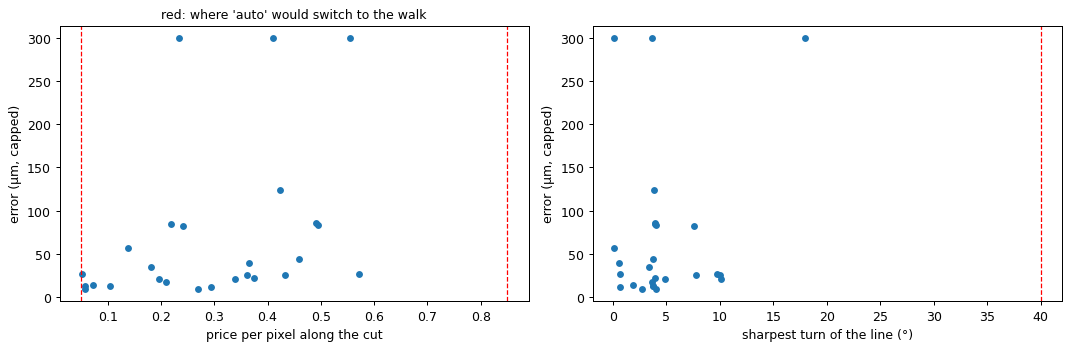

In [23]:
# Could the cut's own signs have told the bad cuts from the good ones?
cut_rows = walk[walk["variant"] == order[0]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, low, high, title in ((axes[0], "cut_price", jn.AUTO_PRICE_LOW, jn.AUTO_PRICE_HIGH, "price per pixel along the cut"),
                                  (axes[1], "sharpest_turn", None, jn.AUTO_TURN_DEG, "sharpest turn of the line (°)")):
    ax.scatter(cut_rows[key], cut_rows["error"], s=20)
    for x in (low, high):
        if x is not None:
            ax.axvline(x, color="red", ls="--", lw=1)
    ax.set_xlabel(title); ax.set_ylabel("error (µm, capped)")
axes[0].set_title("red: where 'auto' would switch to the walk")
plt.tight_layout()
bad = cut_rows["error"] > 150
print("cut price, bad cuts:", cut_rows.loc[bad, "cut_price"].round(2).tolist(),
      "| good cuts range:", cut_rows.loc[~bad, "cut_price"].min().round(2), "–", cut_rows.loc[~bad, "cut_price"].max().round(2))

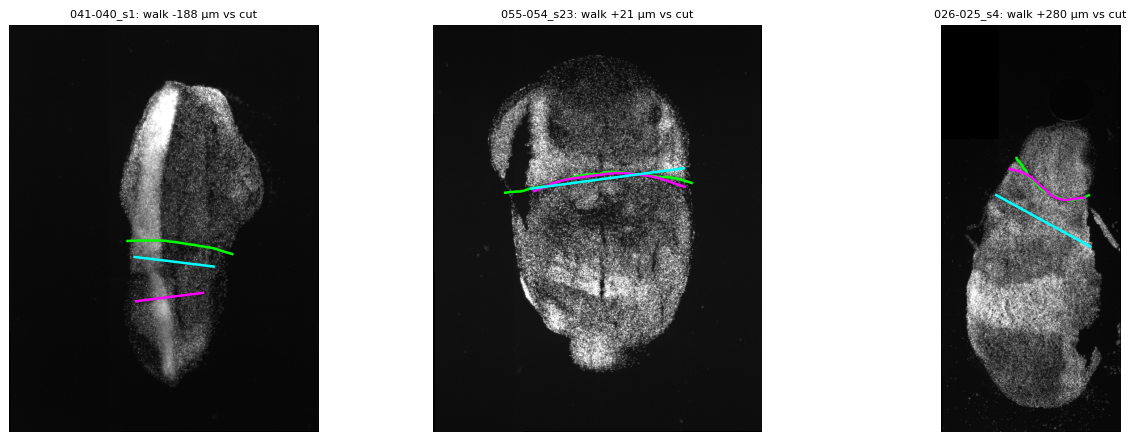

In [24]:
# Three samples, the cut (magenta) and the walk with bending (cyan) against the hand-drawn line (green).
lines = {(r["variant"], r["name"]): r.get("line") for r in walk_rows}
show_names = (walk[walk.variant == "walk + bending"].set_index("name")["error"] - base).sort_values()
picked = [show_names.index[0], show_names.index[len(show_names) // 2], show_names.index[-1]]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axes, picked):
    data = np.load(OUT / f"{name}.npz")
    um, stain = float(data["um"]), data["stain"].astype(np.float32)
    ax.imshow(stain, cmap="gray", vmax=np.percentile(stain[stain > 0], 99.5))
    ax.plot(data["manual_line"][:, 1] / um, data["manual_line"][:, 0] / um, color="lime", lw=2)
    for variant, colour in ((order[0], "magenta"), ("walk + bending", "cyan")):
        line = lines.get((variant, name))
        if line:
            line = np.asarray(line)
            ax.plot(line[:, 1] / um, line[:, 0] / um, color=colour, lw=2)
    ax.set_title(f"{name.split('Asssembloid_')[-1]}: walk {show_names[name]:+.0f} µm vs cut", fontsize=9)
    ax.set_axis_off()
plt.tight_layout()

### What the random walk showed (20 October 2026)

- **The walk is worse than the cut, at every strength tried.** Mean capped error 156–171 µm against 98, median 114–149 against 39, about twice as many failures (12–15 against 7); the walk lands closer to the hand-drawn line than the cut on 2–5 samples and further on 16–21. Smoothing its boundary with the bending pass helps it a little but not enough.
- **Why:** the walk weighs the whole tissue, not just the cheapest path, so it settles roughly *between the seeds* — where a diffusion from each would meet — and is only weakly pulled onto the dark line; the dark line is a gentle dip in price, not the sharp wall a random walker needs. The cut, by summing the price *along* itself, is what finds a faint continuous line, and that matters more here than ignoring tears.
- **The fallback never switched**, and could not have helped: the cut's own signs do not tell the bad cuts from the good ones. The failed cuts have prices of 0.23–0.55 per pixel, inside the range of the good ones (0.05–0.71), and after the bending pass even the bad lines turn by less than 18°. A cut that goes wrong goes wrong *smoothly*, along something that looks like a junction.

So the cut stays (`split_method="cut"`, the default); the walk and the fallback stay in `junction.py` as options, off. This adds to the conclusion of the tuning: the finder cannot tell a wrong line from a right one from the image cues it uses — which is what a model trained on the hand-drawn lines would have to learn.

## Does it matter for the counts? Triage and downstream agreement

Line distance and Dice measure the *line*. What the study reports is the **cells in the band**: how many, and what share is positive per channel. So the question that decides whether the automatic band can be used is whether it changes those numbers by more than matters.

Two parts:

1. **Triage.** Every sample here passed the pre-screen. Which of them should go straight to drawing by hand, and does the finder's own status catch its failures?
2. **Downstream agreement.** Each annotated sample counted twice by the junction analysis with its default settings — in the hand-drawn region and in the finder's band (`junction_downstream.py`, Cellpose on the GPU). Each count sets its own threshold from its own cells, as a real run does.

In [25]:
# 1. Triage: which rule sends the failures, and only them, to be drawn by hand?
cur = pd.read_csv(OUT / "scores.csv")
cur = cur[(cur["variant"] == "bend 1000") & ~cur["name"].isin(jt.EXCLUDE)].copy()
cur["error"] = [jt.capped(r) for r in cur.to_dict("records")]
cur = cur.merge(picks[["name", "Shape"]], on="name", how="left")
flags = cur["flags"].fillna("")
cur["failed"] = cur["error"] > 100
rules = {
    "status is not ok (check or fail)": cur["status"] != "ok",
    "status is fail": cur["status"] == "fail",
    "Shape is Damaged": cur["Shape"] == "Damaged",
    "status is fail, or Shape is Damaged": (cur["status"] == "fail") | (cur["Shape"] == "Damaged"),
}
triage = pd.DataFrame({
    "sent to drawing": {k: int(m.sum()) for k, m in rules.items()},
    "failures caught": {k: f"{int((m & cur.failed).sum())} of {int(cur.failed.sum())}" for k, m in rules.items()},
    "good lines sent anyway": {k: int((m & ~cur.failed).sum()) for k, m in rules.items()},
})
cur["routed"] = rules["status is fail, or Shape is Damaged"]
display(triage)
print("missed:", cur.loc[cur.failed & ~cur.routed, ["name", "error", "status", "Shape"]].to_dict("records"))
print("the 'labelled cells on both sides' flag, good vs failed:",
      int((flags.str.contains("both sides") & ~cur.failed).sum()), "vs", int((flags.str.contains("both sides") & cur.failed).sum()))

,sent to drawing,failures caught,good lines sent anyway
status is not ok (check or fail),21,7 of 8,14
status is fail,4,4 of 8,0
Shape is Damaged,5,5 of 8,0
"status is fail, or Shape is Damaged",7,7 of 8,0


missed: [{'name': '2025_09_26_Asssembloid_034-033_s17', 'error': 300.0, 'status': 'ok', 'Shape': 'Fused pair'}]
the 'labelled cells on both sides' flag, good vs failed: 12 vs 3


In [26]:
# 2. Downstream: the same counts in the hand-drawn band and the automatic one.
rows = [_json.loads(l) for l in (OUT / "downstream.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
down = pd.DataFrame([r for r in rows if r["name"] not in jt.EXCLUDE and r["band"] in ("manual", "automatic")])
channels = sorted({c[:-2] for c in down.columns if c.endswith(" %")})
wide = down.pivot(index="name", columns="band")
pairs = pd.DataFrame(index=wide.index)
pairs["found"] = wide[("error", "automatic")].fillna("") == ""
pairs["cells, manual"] = wide[("n_cells", "manual")]
pairs["cells, automatic"] = wide[("n_cells", "automatic")]
for ch in channels:
    pairs[f"{ch} %, manual"] = wide[(f"{ch} %", "manual")]
    pairs[f"{ch} %, automatic"] = wide[(f"{ch} %", "automatic")]
pairs = pairs.join(cur.set_index("name")[["error", "routed", "Shape"]])
print(f"{len(pairs)} samples counted; automatic band found on {int(pairs.found.sum())}")


def agreement(frame, label):
    out = {}
    for ch in channels:
        m, a = frame[f"{ch} %, manual"], frame[f"{ch} %, automatic"]
        ok = m.notna() & a.notna()
        d = (a - m)[ok]
        between = m[ok].std()
        out[(label, ch)] = {
            "n": int(ok.sum()),
            "% positive, manual (median)": m[ok].median(),
            "difference, mean (pp)": d.mean(),
            "limits of agreement (pp)": f"{d.mean() - 1.96 * d.std():.2f} to {d.mean() + 1.96 * d.std():.2f}",
            "|difference|, median (pp)": d.abs().median(),
            "spread between samples, SD (pp)": between,
            "difference / spread": d.std() / between if between else np.nan,
            "Spearman": stats.spearmanr(m[ok], a[ok]).statistic if ok.sum() > 2 else np.nan,
        }
    return out


counted = pairs[pairs.found]
table_down = pd.DataFrame({**agreement(counted, "all found"),
                           **agreement(counted[~counted.routed], "kept by triage")}).T
table_down.round(2)

30 samples counted; automatic band found on 26


n % positive, manual (median) difference, mean (pp)  \
all found      AF488  26                    1.854043             -0.400585   
               AF555  26                    5.791205             -0.459481   
kept by triage AF488  23                    2.002328              0.038471   
               AF555  23                    5.862971             -0.201727   

                     limits of agreement (pp) |difference|, median (pp)  \
all found      AF488            -5.27 to 4.47                  0.553729   
               AF555            -4.22 to 3.30                  0.808285   
kept by triage AF488            -1.98 to 2.06                  0.497865   
               AF555            -2.17 to 1.77                  0.750012   

                     spread between samples, SD (pp) difference / spread  \
all found      AF488                        3.593795            0.690873   
               AF555                        3.671082            0.523075   
kept by triage AF488                        3.019531            0.341779   
               AF555                        3.546269            0.283528   

                      Spearman  
all found      AF488  0.902222  
               AF555  0.839316  
kept by triage AF488  0.952569  
               AF555  0.925889

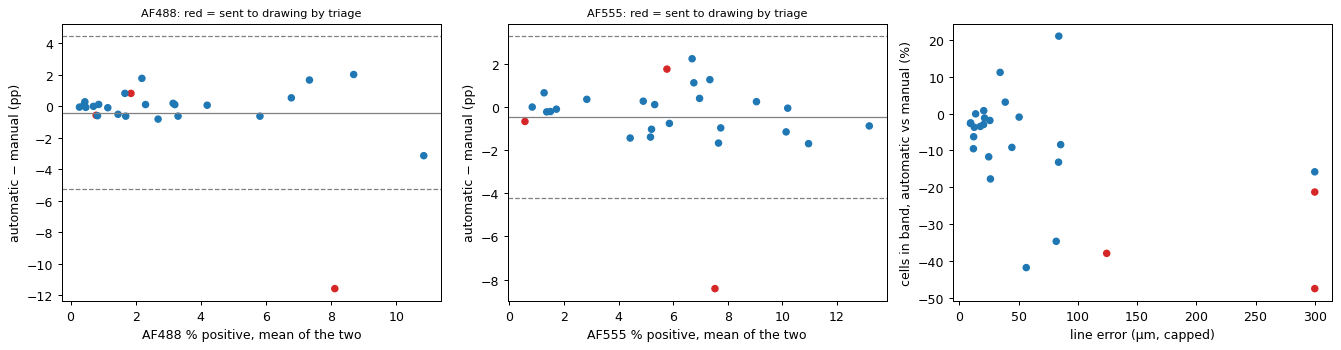

In [27]:
# Bland-Altman per channel: the automatic band minus the hand-drawn one, against their mean.
fig, axes = plt.subplots(1, len(channels) + 1, figsize=(5 * (len(channels) + 1), 4))
for ax, ch in zip(axes, channels):
    m, a = counted[f"{ch} %, manual"], counted[f"{ch} %, automatic"]
    colour = np.where(counted.routed, "tab:red", "tab:blue")
    ax.scatter((m + a) / 2, a - m, c=colour, s=25)
    d = (a - m).dropna()
    for y, style in ((d.mean(), "-"), (d.mean() - 1.96 * d.std(), "--"), (d.mean() + 1.96 * d.std(), "--")):
        ax.axhline(y, color="grey", ls=style, lw=1)
    ax.set_xlabel(f"{ch} % positive, mean of the two"); ax.set_ylabel("automatic − manual (pp)")
    ax.set_title(f"{ch}: red = sent to drawing by triage", fontsize=9)
ax = axes[-1]
ax.scatter(counted["error"], (counted["cells, automatic"] - counted["cells, manual"]) / counted["cells, manual"] * 100,
           c=np.where(counted.routed, "tab:red", "tab:blue"), s=25)
ax.set_xlabel("line error (µm, capped)"); ax.set_ylabel("cells in band, automatic vs manual (%)")
plt.tight_layout()

In [28]:
# The workflow as proposed: the finder's band, except where triage sends the sample to be drawn.
workflow = counted.copy()
for ch in channels:
    workflow[f"{ch} %, workflow"] = np.where(workflow.routed, workflow[f"{ch} %, manual"], workflow[f"{ch} %, automatic"])
    d = workflow[f"{ch} %, workflow"] - workflow[f"{ch} %, manual"]
    print(f"{ch}: workflow vs all hand-drawn — mean {d.mean():+.2f} pp, |diff| median {d.abs().median():.2f} pp, "
          f"max {d.abs().max():.2f} pp; samples off by > 1 pp: {int((d.abs() > 1).sum())} of {len(d)}")
print(f"drawn by hand: {int(workflow.routed.sum())} of {len(workflow)} "
      f"(+ {int((~pairs.found & ~pairs.routed).sum())} with no automatic band outside the rule)")

AF488: workflow vs all hand-drawn — mean +0.03 pp, |diff| median 0.25 pp, max 3.13 pp; samples off by > 1 pp: 4 of 26
AF555: workflow vs all hand-drawn — mean -0.18 pp, |diff| median 0.54 pp, max 2.25 pp; samples off by > 1 pp: 9 of 26
drawn by hand: 3 of 26 (+ 0 with no automatic band outside the rule)


### What it showed (21 October 2026)

**Triage.** All 30 samples (s20 excluded) passed the pre-screen, yet 8 junctions failed (> 100 µm off). The finder's *check* status is no use for triage: it sends 21 of 30, 14 of them fine — the "labelled cells on both sides" flag sits on 12 good lines and 3 bad. **"Status is fail, or Shape is Damaged"** sends 7 samples, all 7 real failures, and no good line. It misses one (`034-033_s17`: status ok, line wrong), which only a look at the QC picture catches. Found on these same 30 samples, with 5 Damaged: to be confirmed on the next batch.

**Downstream.** On the 23 samples triage would keep, the automatic band gives the same counts *on average*: mean difference +0.04 pp (AF488) and −0.20 pp (AF555) in % positive, median absolute difference 0.5 and 0.75 pp, Spearman 0.95 and 0.93. Per sample the limits of agreement are about ±2 pp — about a third of how much % positive varies between samples (SD 3.0–3.5 pp), but not small next to a median of 2–6 % positive. Some of that is the threshold: each band sets its own from its own cells.

The workflow as proposed — the finder's band, drawn by hand where triage says — against every band drawn by hand: mean +0.03 / −0.18 pp, median |difference| 0.25 / 0.54 pp, worst sample 3.1 pp; 7 of 30 drawn by hand.

**Decision.**
- Use the finder on pass samples, draw by hand where status is fail or Shape is Damaged, glance at every other QC picture (accept / redraw). No more parameter tuning.
- Fine for **group comparisons** (no bias; per-sample noise averages out over samples). For a claim about a **single sample**, or if the expected difference between groups is around 1–2 pp, draw that sample's band by hand.
- Still missing: how much two people drawing the same junction disagree. If that is ±2 pp too, the finder is as good as a second annotator.

## Two people, one junction: how far apart are two annotators?

The finder is off from the hand-drawn line by a median 34 µm, and its band changes % positive by about ±2 pp per sample. Whether that is good or bad depends on how much **two people** drawing the same junction differ. A second annotator redraws a subset, stored as `manual annotated junction region quillan` (`jt.SECOND_KEY`). On those samples, three comparisons with the same metrics:

- **second vs first annotator** — the floor: what disagreement between people looks like;
- **finder vs first annotator** — what everything above measured;
- **finder vs second annotator**.

If the finder is about as far from either person as they are from each other, it is as good as a second annotator. Rerun `python notebooks/validation/junction_downstream.py` after drawing more: it counts only the new bands.

In [29]:
from microscopy_viewer import ims_store

second = []
for row in samples.itertuples():
    if jt.SECOND_KEY not in ims_store.list_labels(row.path):
        continue
    labels, attrs = ims_store.load_labels(row.path, jt.SECOND_KEY)
    overview, first_band, first_line, base = jt.load_case(row.name)
    step = overview.step
    shape = first_band.shape
    second_band = (np.asarray(labels).reshape(np.shape(labels)[-2:])[::step, ::step] > 0)[: shape[0], : shape[1]]
    second_line = np.asarray(attrs["line_yx_um"], dtype=float).reshape(-1, 2)
    result = jn.find_junction(overview, jn.JunctionOptions(save=False, **base))
    um = overview.um
    region = ndimage.binary_dilation(jn.tissue_of(overview), iterations=max(1, int(np.ceil(base["margin_um"] / um))))
    pairs_of = {"second vs first": (second_line, second_band, first_line, first_band)}
    if result.line_um is not None and result.band is not None:
        pairs_of["finder vs first"] = (result.line_um, result.band, first_line, first_band)
        pairs_of["finder vs second"] = (result.line_um, result.band, second_line, second_band)
    for pair, (line_a, band_a, line_b, band_b) in pairs_of.items():
        mean_dist, hd95, within100 = jt.line_distance(line_b, line_a, region, um)
        second.append({"name": row.name, "pair": pair, "mean_dist": mean_dist, "hd95": hd95,
                       "within100": within100, "dice": dice(band_a & region, band_b & region)})
second = pd.DataFrame(second)
print(f"{second['name'].nunique()} sample(s) drawn by both annotators")
if len(second):
    display(second.groupby("pair", sort=False)[["mean_dist", "hd95", "within100", "dice"]]
            .agg(["median", "mean"]).round(2))
    display(second.pivot(index="name", columns="pair", values="mean_dist").round(0))

27 sample(s) drawn by both annotators


mean_dist          hd95         within100         dice      
                    median   mean median    mean    median  mean median  mean
pair                                                                         
second vs first      17.36  40.39  37.78   92.35       1.0  0.93   0.94  0.88
finder vs first      26.06  59.64  71.04  128.98       1.0  0.86   0.90  0.82
finder vs second     25.50  64.35  81.25  161.57       1.0  0.85   0.91  0.82

pair,finder vs first,finder vs second,second vs first
name,,,
2025_09_26_Asssembloid_019-018_s10,17.0,8.0,20.0
2025_09_26_Asssembloid_020-019_s4,105.0,108.0,11.0
2025_09_26_Asssembloid_026-025_s4,20.0,25.0,10.0
2025_09_26_Asssembloid_026-025_s8,26.0,17.0,9.0
2025_09_26_Asssembloid_027-026_s5,40.0,43.0,5.0
2025_09_26_Asssembloid_031-030_s7,40.0,31.0,36.0
2025_09_26_Asssembloid_033-032_s12,127.0,129.0,6.0
2025_09_26_Asssembloid_034-033_s13,15.0,338.0,346.0
2025_09_26_Asssembloid_034-033_s17,341.0,357.0,32.0


In [30]:
# The counts: % positive in each person's band and in the finder's, per channel.
both = pd.DataFrame([r for r in rows if r["name"] not in jt.EXCLUDE])
both = both[both["name"].isin(both.loc[both["band"] == "second", "name"])]
if both.empty:
    print("no second annotation counted yet: run  python notebooks/validation/junction_downstream.py")
else:
    per = both.pivot(index="name", columns="band")
    out = {}
    for ch in channels:
        for pair, (a, b) in {"second vs first": ("second", "manual"), "finder vs first": ("automatic", "manual"),
                             "finder vs second": ("automatic", "second")}.items():
            d = (per[(f"{ch} %", a)] - per[(f"{ch} %", b)]).dropna()
            out[(ch, pair)] = {"n": len(d), "mean (pp)": d.mean(), "|difference|, median (pp)": d.abs().median(),
                               "|difference|, max (pp)": d.abs().max(), "SD of difference (pp)": d.std()}
    display(pd.DataFrame(out).T.round(2))

n  mean (pp)  |difference|, median (pp)  \
AF488 second vs first   27.0      -0.10                       0.15   
      finder vs first   25.0      -0.42                       0.56   
      finder vs second  25.0      -0.28                       0.31   
AF555 second vs first   27.0      -0.06                       0.32   
      finder vs first   25.0      -0.47                       0.87   
      finder vs second  25.0      -0.31                       0.44   

                        |difference|, max (pp)  SD of difference (pp)  
AF488 second vs first                     2.27                   0.61  
      finder vs first                    11.57                   2.53  
      finder vs second                    9.30                   2.09  
AF555 second vs first                     3.81                   1.12  
      finder vs first                     8.42                   1.96  
      finder vs second                    6.98                   1.68

27 samples drawn by both; 5 routed to drawing by triage, 1 with no automatic line
kept by triage (22): finder within the two people's own distance on 8 (vs first) and 11 (vs second); within 2× on 14


n  median (µm)  mean (µm)  > 100 µm
all, line found second vs first   26.0         18.1       41.6       2.0
                finder vs first   26.0         26.1       59.6       4.0
                finder vs second  26.0         25.5       64.4       5.0
kept by triage  second vs first   22.0         16.1       36.9       1.0
                finder vs first   22.0         25.5       45.9       2.0
                finder vs second  22.0         20.8       56.0       3.0

% positive, samples kept by triage:

n mean (pp) |difference|, median (pp)  \
AF488 second vs first   22 -0.031862                  0.145126   
      finder vs first   22  0.034957                  0.522351   
      finder vs second  22  0.066819                  0.258562   
AF555 second vs first   22 -0.179034                  0.219367   
      finder vs first   22 -0.201884                  0.808285   
      finder vs second  22  -0.02285                  0.436432   

                       limits of agreement (pp)       CCC  
AF488 second vs first             -0.87 to 0.81   0.99029  
      finder vs first             -2.04 to 2.11  0.939753  
      finder vs second            -1.83 to 1.96  0.949362  
AF555 second vs first             -2.34 to 1.98  0.947009  
      finder vs first             -2.22 to 1.82  0.951666  
      finder vs second            -2.00 to 1.95  0.953588

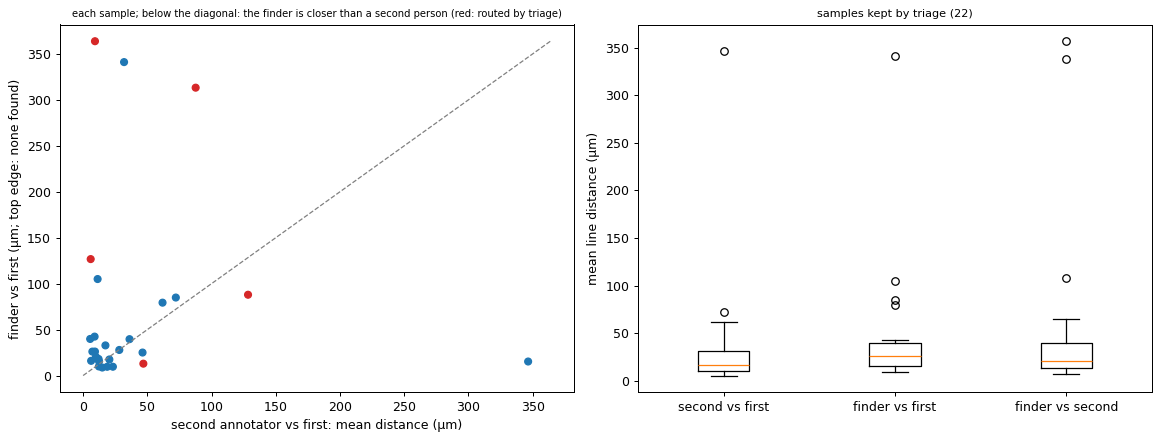

In [31]:

def ccc_(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    ok = np.isfinite(a) & np.isfinite(b)
    a, b = a[ok], b[ok]
    return 2 * np.cov(a, b, bias=True)[0, 1] / (a.var() + b.var() + (a.mean() - b.mean()) ** 2) if len(a) > 2 else np.nan

# Per sample: is the finder as close to the first annotator as the second annotator is?
lines = second.pivot(index="name", columns="pair", values="mean_dist")
lines["routed by triage"] = lines.index.isin(cur.loc[cur["routed"], "name"])
lines["no junction found"] = lines["finder vs first"].isna()
kept = lines[~lines["routed by triage"] & ~lines["no junction found"]]
print(f"{len(lines)} samples drawn by both; {int(lines['routed by triage'].sum())} routed to drawing by triage, "
      f"{int(lines['no junction found'].sum())} with no automatic line")
print(f"kept by triage ({len(kept)}): finder within the two people's own distance on "
      f"{int((kept['finder vs first'] <= kept['second vs first']).sum())} (vs first) and "
      f"{int((kept['finder vs second'] <= kept['second vs first']).sum())} (vs second); "
      f"within 2× on {int((kept['finder vs first'] <= 2 * kept['second vs first']).sum())}")
summary = {}
for label_, frame in (("all, line found", lines[~lines["no junction found"]]), ("kept by triage", kept)):
    for pair in ("second vs first", "finder vs first", "finder vs second"):
        summary[(label_, pair)] = {"n": int(frame[pair].notna().sum()), "median (µm)": frame[pair].median(),
                                   "mean (µm)": frame[pair].mean(), "> 100 µm": int((frame[pair] > 100).sum())}
display(pd.DataFrame(summary).T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
top = np.nanmax(lines[["second vs first", "finder vs first"]].to_numpy()) * 1.05
colour = np.where(lines["routed by triage"], "tab:red", "tab:blue")
ax.scatter(lines["second vs first"], lines["finder vs first"].fillna(top), c=colour, s=30)
ax.plot([0, top], [0, top], color="grey", ls="--", lw=1)
ax.set_xlabel("second annotator vs first: mean distance (µm)"); ax.set_ylabel("finder vs first (µm; top edge: none found)")
ax.set_title("each sample; below the diagonal: the finder is closer than a second person (red: routed by triage)", fontsize=8)
ax = axes[1]
per_pair = [kept[p].dropna() for p in ("second vs first", "finder vs first", "finder vs second")]
ax.boxplot(per_pair, showfliers=True)
ax.set_xticks([1, 2, 3], ["second vs first", "finder vs first", "finder vs second"])
ax.set_ylabel("mean line distance (µm)"); ax.set_title(f"samples kept by triage ({len(kept)})", fontsize=9)
plt.tight_layout()

# The counts on the kept samples only.
if not both.empty:
    keep_names = set(kept.index)
    per_k = per[per.index.isin(keep_names)]
    out = {}
    for ch in channels:
        for pair, (a, b) in {"second vs first": ("second", "manual"), "finder vs first": ("automatic", "manual"),
                             "finder vs second": ("automatic", "second")}.items():
            d = (per_k[(f"{ch} %", a)] - per_k[(f"{ch} %", b)]).dropna()
            out[(ch, pair)] = {"n": len(d), "mean (pp)": d.mean(), "|difference|, median (pp)": d.abs().median(),
                               "limits of agreement (pp)": f"{d.mean() - 1.96 * d.std():.2f} to {d.mean() + 1.96 * d.std():.2f}",
                               "CCC": ccc_(per_k[(f"{ch} %", a)], per_k[(f"{ch} %", b)])}
    print("% positive, samples kept by triage:")
    display(pd.DataFrame(out).T.round(2))

### What it showed (21 October 2026: 27 samples drawn by both)

**The two people agree closely.** Median line distance 15 µm (mean 28), Dice 0.95; only one sample more than 100 µm apart (`037-036_s25`, Damaged, 128 µm). On % positive in the band: AF488 within −0.9 to +0.8 pp (CCC 0.99), AF555 within −2.3 to +2.0 pp (CCC 0.95), on the samples triage keeps.

**The finder, on the 22 samples triage keeps** (fail or Damaged go to drawing):

| | second vs first | finder vs first | finder vs second |
|---|---|---|---|
| line distance, median | 14 µm | 25 µm | 17 µm |
| > 100 µm | 0 | 1 (`034-033_s17`) | 1 |
| AF488 % positive, limits of agreement | ±0.85 pp | ±2.1 pp | ±1.9 pp |
| AF555 % positive, limits of agreement | ±2.2 pp | ±2.0 pp | ±2.0 pp |

- On the **line**, the finder is about 1.2–1.8× as far from a person as the two people are from each other — within the people's own distance on 4–10 of 22 samples, within twice it on 14. It is closer to the second annotator than to the first.
- On the **counts**, for AF555 it is **as good as a second annotator** (±2 pp either way, no bias). For AF488 the two people agree better than the finder does (±0.9 against ±2 pp): the AF488 count is the one that depends on exactly where the line is.
- The one large miss among the kept samples is `034-033_s17`, where both people agree (18 µm) and the finder is 345 µm off with status *ok* — what the glance at every QC picture is for.

**So:** the finder with triage is good enough for group comparisons of AF555, and close for AF488 — no bias, and per-sample noise about twice a second person's. If AF488 per sample is a headline number, keep the review step strict for it (redraw anything visibly off), or draw those by hand.

## Tissue from every channel

**The problem.** In the whole-dataset run (`2025_09_26_Asssembloid_019-018_s7`) the junction stopped well short of the section's outline. The tissue mask comes from the nuclear stain alone, and one organoid of that pair is faint in AF405: most of it fell below the cut, so the mask — and the cut, and the line drawn along it — ended where the bright organoid did. A faint nuclear stain in one organoid of a pair is common.

**The change.** `tissue_mask` now takes the other channels too: tissue is wherever *any* channel stands above the slide (each channel thresholded as the nuclear one is, a fifth of the way from background to tissue), then opened, closed and cleaned as before. Option `tissue_all_channels` (`TISSUE_ALL_CHANNELS`), the panel's *Find the tissue in every channel*. Run by `junction_tissue.py` on the 30 annotated samples, both variants, everything else at the defaults; `junction_eval/tissue.jsonl`.

In [32]:
tissue = pd.read_json(OUT / "tissue.jsonl", lines=True)
print("capped mean distance (µm; no junction = 300):")
display(tissue.pivot_table(index="variant", columns="set", values="capped", aggfunc=["mean", "median"]).round(1))
print("medians over all samples:")
display(tissue.groupby("variant")[["capped", "hd95", "within100", "dice"]].median().round(3))
print("status:")
display(pd.crosstab(tissue["variant"], tissue["status"]))
wide_t = tissue.pivot(index="name", columns="variant", values="capped")
wide_t["change"] = wide_t["all channels"] - wide_t["nuclear only"]
wide_t["set"] = tissue.drop_duplicates("name").set_index("name")["set"]
print("per sample, sorted by the change (negative = better from every channel):")
display(wide_t.sort_values("change").round(1))

capped mean distance (µm; no junction = 300):


mean          median       
set          held out tuning held out tuning
variant                                     
all channels    116.4   49.3     67.0   26.1
nuclear only    171.6   73.3    190.9   26.0

medians over all samples:


,capped,hd95,within100,dice
variant,,,,
all channels,29.378,76.172,1.000,0.897
nuclear only,36.558,88.423,0.966,0.879


status:


status,check,fail,ok
variant,,,
all channels,18,1,11
nuclear only,17,4,9


per sample, sorted by the change (negative = better from every channel):


variant,all channels,nuclear only,change,set
name,,,,
2025_09_26_Asssembloid_045-044_s16,12.9,300.0,-287.1,tuning
2025_09_26_Asssembloid_052-051_s23,30.9,300.0,-269.1,tuning
2025_09_26_Asssembloid_044-043_s19,91.6,300.0,-208.4,held out
2025_09_26_Asssembloid_033-032_s12,126.7,300.0,-173.3,held out
2025_09_26_Asssembloid_019-018_s10,17.5,81.7,-64.3,held out
2025_09_26_Asssembloid_052-051_s18,9.6,56.4,-46.9,tuning
2025_09_26_Asssembloid_037-036_s25,87.9,124.3,-36.4,tuning
2025_09_26_Asssembloid_039-038_s5,79.3,85.5,-6.2,tuning
2025_09_26_Asssembloid_054-053_s7,8.7,13.8,-5.1,tuning


### What it showed (22 October 2026, 30 samples)

- **Better on both sets.** Capped mean error 73 → 49 µm on the tuning set and **172 → 116 µm held out**; median HD95 88 → 76 µm, Dice 0.88 → 0.90. Fails 4 → 1.
- **Where it helps, it helps a lot.** Four samples that had no usable line (capped at 300 µm) now come within 13–127 µm of the hand-drawn one (045-044_s16, 052-051_s23, 044-043_s19, 033-032_s12), and three more improve by 35–65 µm. These are the pairs with one organoid faint in the nuclear stain.
- **Where it hurts.** One sample is clearly worse: 020-019_s4, 26 → 105 µm. The outline barely changes, but the cut moves up onto the labelled organoid. A few others move by 5–15 µm either way.
- **Decision: `TISSUE_ALL_CHANNELS = True` is the default.** The held-out error improves, which is the rule for changing a default. The new baseline is a median of 29 µm, HD95 76 µm. The whole-dataset run of 21 October used the old mask, so its sections with a faint organoid have short lines and bands.
- **What it does not fix.** In 019-018_s7 the line now runs edge to edge, but it cuts across the faint organoid's corner rather than following the junction. That pair has no dark seam, so the cheapest cut is the shortest one next to the small second seed. That is the "no clear junction" problem, which is separate from this one.

## No clear junction: seeds from the labels, and a fallback when there is no seam

**The problem.** The cut follows the dark seam the nuclear stain shows between two organoids. Where there is none, the cheapest cut is simply the shortest one between the seeds — and the seeds are each organoid's densest core, so the cut runs round whichever core is smaller, often across a corner of one organoid (019-018_s7 after the tissue fix).

**Telling when there is no seam.** The cut's *seam price* is the mean line price under it (1 = plain tissue, lower = darker than its surroundings). On the 30 samples, every cut with a seam price above 0.4 is poor (25–300 µm, five of six above 75 µm). It becomes a flag, *no dark line at the junction*, on by default.

**What was tried** (`junction_seam.py`, `junction_eval/seam.jsonl`; everything else at the defaults):
- **dominant seeds** (`seed_rule="dominant"`, `dominant_seeds`): each seed is all the tissue where its own label leads the other's by 0.25 (both scaled 0–1), not only the dense core, so the cut is left only the mixed strip between them;
- **the cells' edge** (`edge_weight` 0.5): cutting costs more where the labels are at either organoid's own level;
- **a fallback** (`no_seam_price`): only when the first cut's seam price is above 0.3 or 0.4, the junction is found again with dominant seeds (and edge weight 0 or 0.5).

In [33]:
seam = pd.read_json(OUT / "seam.jsonl", lines=True)
order = list(dict.fromkeys(seam["variant"]))
table = seam.pivot_table(index="variant", columns="set", values="capped", aggfunc="mean").loc[order]
table["all (sum)"] = seam.groupby("variant")["capped"].sum().loc[order]
table["median HD95"] = seam.groupby("variant")["hd95"].median().loc[order]
print("capped mean distance (µm; no junction = 300):")
display(table.round(1))
first = seam[seam["variant"] == "default"].set_index("name")
wide_s = seam.pivot(index="name", columns="variant", values="capped")[order]
wide_s["seam price (default cut)"] = first["cut_price"]
wide_s["set"] = first["set"]
print("per sample, by the default cut's seam price:")
display(wide_s.sort_values("seam price (default cut)").round(2))
flagged = first["cut_price"] > 0.4
bad = first["capped"] > 75
print(f"'no dark line' flag: on {int(flagged.sum())} samples, {int((flagged & bad).sum())} of them > 75 µm off; "
      f"{int((~flagged & bad).sum())} lines > 75 µm off are not flagged (held-out samples flagged: "
      f"{int((flagged & (first['set'] == 'held out')).sum())})")

capped mean distance (µm; no junction = 300):


set,held out,tuning,all (sum),median HD95
variant,,,,
default,116.4,49.3,2014.8,76.2
dominant seeds,96.1,80.1,2530.8,92.1
dominant seeds + edge 0.5,137.4,85.3,2975.4,125.7
core seeds + edge 0.5,121.5,75.3,2628.6,90.2
no seam > 0.4: dominant seeds,116.4,51.8,2070.4,76.2
no seam > 0.4: dominant seeds + edge 0.5,116.4,48.0,1987.5,65.9
no seam > 0.3: dominant seeds + edge 0.5,123.1,48.2,2045.5,60.6


per sample, by the default cut's seam price:


variant,default,dominant seeds,dominant seeds + edge 0.5,core seeds + edge 0.5,no seam > 0.4: dominant seeds,no seam > 0.4: dominant seeds + edge 0.5,no seam > 0.3: dominant seeds + edge 0.5,seam price (default cut),set
name,,,,,,,,,
2025_09_26_Asssembloid_054-053_s7,8.70,8.70,14.23,8.70,8.70,8.70,8.70,0.06,tuning
2025_09_26_Asssembloid_045-044_s4,32.79,62.41,62.41,32.79,32.79,32.79,32.79,0.06,held out
2025_09_26_Asssembloid_055-054_s23,16.00,300.00,300.00,17.37,16.00,16.00,16.00,0.08,tuning
2025_09_26_Asssembloid_055-054_s15,9.52,300.00,300.00,10.60,9.52,9.52,9.52,0.09,tuning
2025_09_26_Asssembloid_045-044_s16,12.91,13.31,60.61,135.49,12.91,12.91,12.91,0.10,tuning
2025_09_26_Asssembloid_052-051_s23,30.93,30.09,30.09,14.14,30.93,30.93,30.93,0.11,tuning
2025_09_26_Asssembloid_052-051_s18,9.58,11.44,11.44,9.58,9.58,9.58,9.58,0.14,tuning
2025_09_26_Asssembloid_050-049_s5,26.04,12.50,26.95,26.04,26.04,26.04,26.04,0.14,tuning
2025_09_26_Asssembloid_034-033_s3,15.50,60.75,60.75,15.50,15.50,15.50,15.50,0.15,tuning


'no dark line' flag: on 6 samples, 5 of them > 75 µm off; 5 lines > 75 µm off are not flagged (held-out samples flagged: 0)


### What it showed (22 October 2026, 30 samples)

- **The flag works.** The seam price separates good cuts from bad ones: of the 6 samples above 0.4, 5 are more than 75 µm off. Below 0.4, 4 of 23 are. The flag is on by default: such samples now show *check* with the reason *no dark line at the junction*. It is a candidate for triage (draw these by hand), but that has not been tested on the downstream counts.
- **Dominant seeds always**: better held out (116 → 96 µm), but much worse on the tuning set (49 → 80 µm). Two clean samples with a seam lose their line entirely (055-054_s23 and s15, 16 → 300 µm). The cut no longer reaches round the cores to the seam, so it is not the default.
- **The cells' edge, always**: worse on both sets (as found before).
- **The fallback** (seam price > 0.4, dominant seeds + edge 0.5): a wash. Total 1987 vs 2015 µm. It rescues 041-040_s1 (300 → 30 µm) but breaks 020-019_s4 (105 → 300 µm) and moves two others by 10–40 µm the wrong way. No held-out sample has a seam price above 0.4, so it cannot be judged held out.
- On the section that prompted it (019-018_s7, not annotated), the fallback and the dominant seeds both put the line on the boundary between the dim and the bright organoid, where the default cut crosses a corner.
- **Decision.** Defaults unchanged: `seed_rule="core"`, `no_seam_price=0`. Both stay in the engine, off. Keep the flag. Thirty samples hold too few no-seam pairs (6) to tune a fallback for them. To decide, draw more of them by hand: pick sections the flag fires on from the whole-dataset run and rerun `junction_seam.py`.

## Shape and seeds: does the outline say where the junction is?

Two organoids that fused leave a waist in the section: notches in the outline where they meet. If the hand-drawn junctions run between such notches, or sit at a fixed place between the seeds, shape could guide the finder where the nuclear stain shows no seam. `junction_morphology.py` measures, per annotated sample, with the finder's defaults:

- **Concavity** of each outline point: how far inside the convex hull it lies (µm). A **notch** is a local maximum at least 20 µm deep. For each end of a junction, where it meets the outline: the deepest concavity within 50 µm along the outline, as a **percentile** of all outline points (50 = a random place on the outline, 100 = the deepest notch), and the distance along the outline to the nearest notch.
- **Seed axis**: from the labelled seed's centre (t = 0) to the other seed's centre (t = 1). The **position** of a junction is the median t of its points on the tissue. The tissue's **width** along the axis is used to find its narrowest point between the seeds.
- **Junctions from shape alone**, scored against the hand-drawn line as the finder is:
  - *notch chord*: the pair of notches that best pinches the tissue between the seeds, with the largest (depth + depth) / length;
  - *square at the narrowest*: a straight line across the axis at the narrowest point;
  - *square halfway*: a straight line across the axis at t = 0.5.

Results in `junction_eval/morphology.csv`, geometry in `morphology.pkl`.

In [34]:
import pickle

morph = pd.read_csv(OUT / "morphology.csv")
geo = pickle.load((OUT / "morphology.pkl").open("rb"))
m = morph.dropna(subset=["t junction"]).copy()
print(f"{len(m)} samples measured ({len(morph) - len(m)} without seeds on the main piece of tissue)")

hand_ends = pd.concat([m["end 0 concavity percentile"], m["end 1 concavity percentile"]]).dropna()
finder_ends = pd.concat([m["finder end 0 concavity percentile"], m["finder end 1 concavity percentile"]]).dropna()
to_notch = pd.concat([m["end 0 to notch (um)"], m["end 1 to notch (um)"]]).dropna()
print(f"hand-drawn ends: median concavity percentile {hand_ends.median():.0f} "
      f"({(hand_ends > 75).mean():.0%} in the top quarter; Wilcoxon against 50: p = {stats.wilcoxon(hand_ends - 50).pvalue:.1g}); "
      f"both ends in the top quarter on {int(((m['end 0 concavity percentile'] > 75) & (m['end 1 concavity percentile'] > 75)).sum())} of {len(m)}")
print(f"finder ends: median percentile {finder_ends.median():.0f} ({(finder_ends > 75).mean():.0%} in the top quarter)")
print(f"along the outline to the nearest notch: hand-drawn ends median {to_notch.median():.0f} µm "
      f"({(to_notch <= 100).mean():.0%} within 100 µm); any outline point median {m['any point to notch (um, median)'].median():.0f} µm")
print(f"\nposition between the seeds: hand-drawn t median {m['t junction'].median():.2f} (SD {m['t junction'].std():.2f}, "
      f"range {m['t junction'].min():.2f}–{m['t junction'].max():.2f}); finder {m['t finder'].median():.2f}; narrowest point {m['t neck'].median():.2f}")
for col in ("labelled share", "t neck"):
    r = stats.spearmanr(m["t junction"], m[col], nan_policy="omit")
    print(f"  t junction vs {col}: Spearman {r[0]:.2f}, p = {r[1]:.2g}")
print(f"angle of the hand-drawn junction to the seed axis: median {m['junction angle to axis (deg)'].median():.0f}° (90 = square across)")

ERR = {"finder": "finder error (um)", "notch chord": "notch chord error (um)",
       "square halfway": "square halfway error (um)", "square at the narrowest": "square at the narrowest error (um)"}
print("\ndistance to the hand-drawn line (µm):")
display(pd.DataFrame({k: m[c].describe()[["count", "50%", "mean"]] for k, c in ERR.items()}).T.round(0))
both = m.dropna(subset=[ERR["finder"], ERR["notch chord"]])
print(f"notch chord closer than the finder on {int((both[ERR['notch chord']] < both[ERR['finder']]).sum())} of {len(both)}:")
display(both.loc[both[ERR["notch chord"]] < both[ERR["finder"]], ["name", ERR["finder"], ERR["notch chord"], "seam price"]].round(2))

print("does the shape predict how far off the finder is? (Spearman with finder error)")
pred = {}
m["finder ends in notches (worse end percentile)"] = m[["finder end 0 concavity percentile", "finder end 1 concavity percentile"]].min(axis=1)
for col in ("seam price", "solidity", "notches", "deepest notch (um)", "neck width / median width",
            "seed distance (um)", "junction angle to axis (deg)", "labelled share", "finder ends in notches (worse end percentile)"):
    r = stats.spearmanr(m[col], m[ERR["finder"]], nan_policy="omit")
    pred[col] = {"rho": r[0], "p": r[1]}
display(pd.DataFrame(pred).T.round(3))

29 samples measured (1 without seeds on the main piece of tissue)
hand-drawn ends: median concavity percentile 91 (74% in the top quarter; Wilcoxon against 50: p = 6e-09); both ends in the top quarter on 17 of 29
finder ends: median percentile 89 (72% in the top quarter)
along the outline to the nearest notch: hand-drawn ends median 34 µm (71% within 100 µm); any outline point median 417 µm

position between the seeds: hand-drawn t median 0.51 (SD 0.11, range 0.30–0.75); finder 0.51; narrowest point 0.67
  t junction vs labelled share: Spearman 0.63, p = 0.00022
  t junction vs t neck: Spearman 0.22, p = 0.26
angle of the hand-drawn junction to the seed axis: median 82° (90 = square across)

distance to the hand-drawn line (µm):


,count,50%,mean
finder,29.0,28.0,61.0
notch chord,26.0,85.0,188.0
square halfway,29.0,138.0,151.0
square at the narrowest,29.0,316.0,337.0


notch chord closer than the finder on 6 of 26:


,name,finder error (um),notch chord error (um),seam price
0,2025_09_26_Asssembloid_020-019_s4,104.99,91.92,0.64
8,2025_09_26_Asssembloid_041-040_s1,313.21,21.74,0.44
14,2025_09_26_Asssembloid_050-049_s5,26.04,8.76,0.14
18,2025_09_26_Asssembloid_053-052_s5,27.83,26.59,0.22
25,2025_09_26_Asssembloid_034-033_s17,341.04,69.10,0.23
27,2025_09_26_Asssembloid_045-044_s4,32.79,30.80,0.06


does the shape predict how far off the finder is? (Spearman with finder error)


,rho,p
seam price,0.608,0.000
solidity,0.070,0.718
notches,-0.216,0.260
deepest notch (um),-0.169,0.381
neck width / median width,-0.194,0.313
seed distance (um),-0.283,0.137
junction angle to axis (deg),-0.328,0.083
labelled share,-0.144,0.455
finder ends in notches (worse end percentile),-0.359,0.056


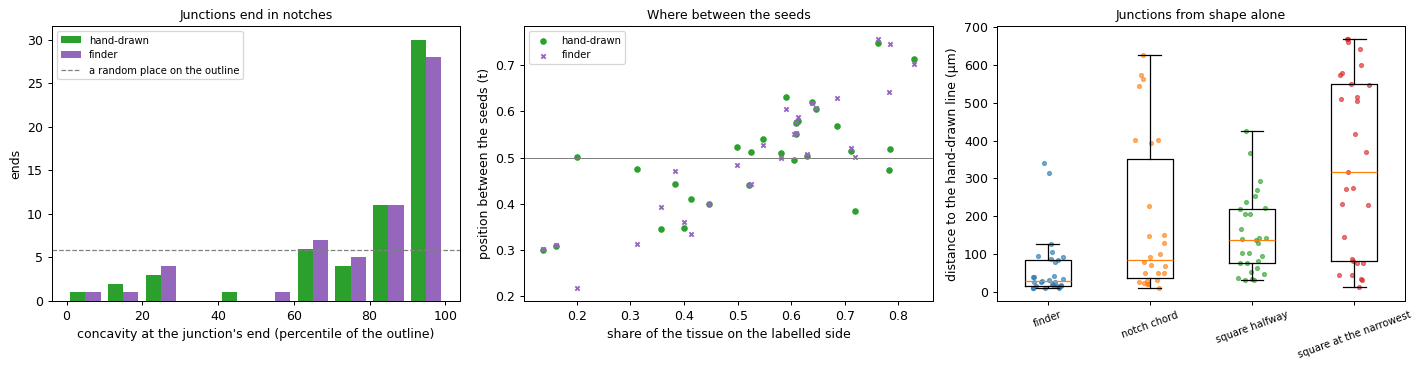

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
bins = np.linspace(0, 100, 11)
axes[0].hist([hand_ends, finder_ends], bins=bins, label=["hand-drawn", "finder"], color=["tab:green", "tab:purple"])
axes[0].axhline(len(hand_ends) / 10, color="grey", ls="--", lw=1, label="a random place on the outline")
axes[0].set_xlabel("concavity at the junction's end (percentile of the outline)"); axes[0].set_ylabel("ends")
axes[0].legend(fontsize=8); axes[0].set_title("Junctions end in notches", fontsize=10)
axes[1].scatter(m["labelled share"], m["t junction"], s=18, color="tab:green", label="hand-drawn")
axes[1].scatter(m["labelled share"], m["t finder"], s=12, color="tab:purple", marker="x", label="finder")
axes[1].axhline(0.5, color="grey", lw=0.8)
axes[1].set_xlabel("share of the tissue on the labelled side"); axes[1].set_ylabel("position between the seeds (t)")
axes[1].legend(fontsize=8); axes[1].set_title("Where between the seeds", fontsize=10)
data = [m[c].dropna().clip(upper=700) for c in ERR.values()]
axes[2].boxplot(data, showfliers=False)
for k, values in enumerate(data):
    axes[2].scatter(np.full(len(values), k + 1) + np.random.default_rng(k).uniform(-0.15, 0.15, len(values)), values, s=10, alpha=0.6)
axes[2].set_xticks(range(1, len(ERR) + 1), list(ERR), rotation=20, fontsize=8)
axes[2].set_ylabel("distance to the hand-drawn line (µm)"); axes[2].set_title("Junctions from shape alone", fontsize=10)
fig.tight_layout()
plt.show()

**Pictures.** The finder's two worst failures, two where the notch chord picks the wrong notches, and two clean samples. Grey: the nuclear stain. Light outline: the convex hull. Dots: notches (size by depth). Green: hand-drawn. Magenta: finder. Orange: notch chord. Red / cyan: the seeds.

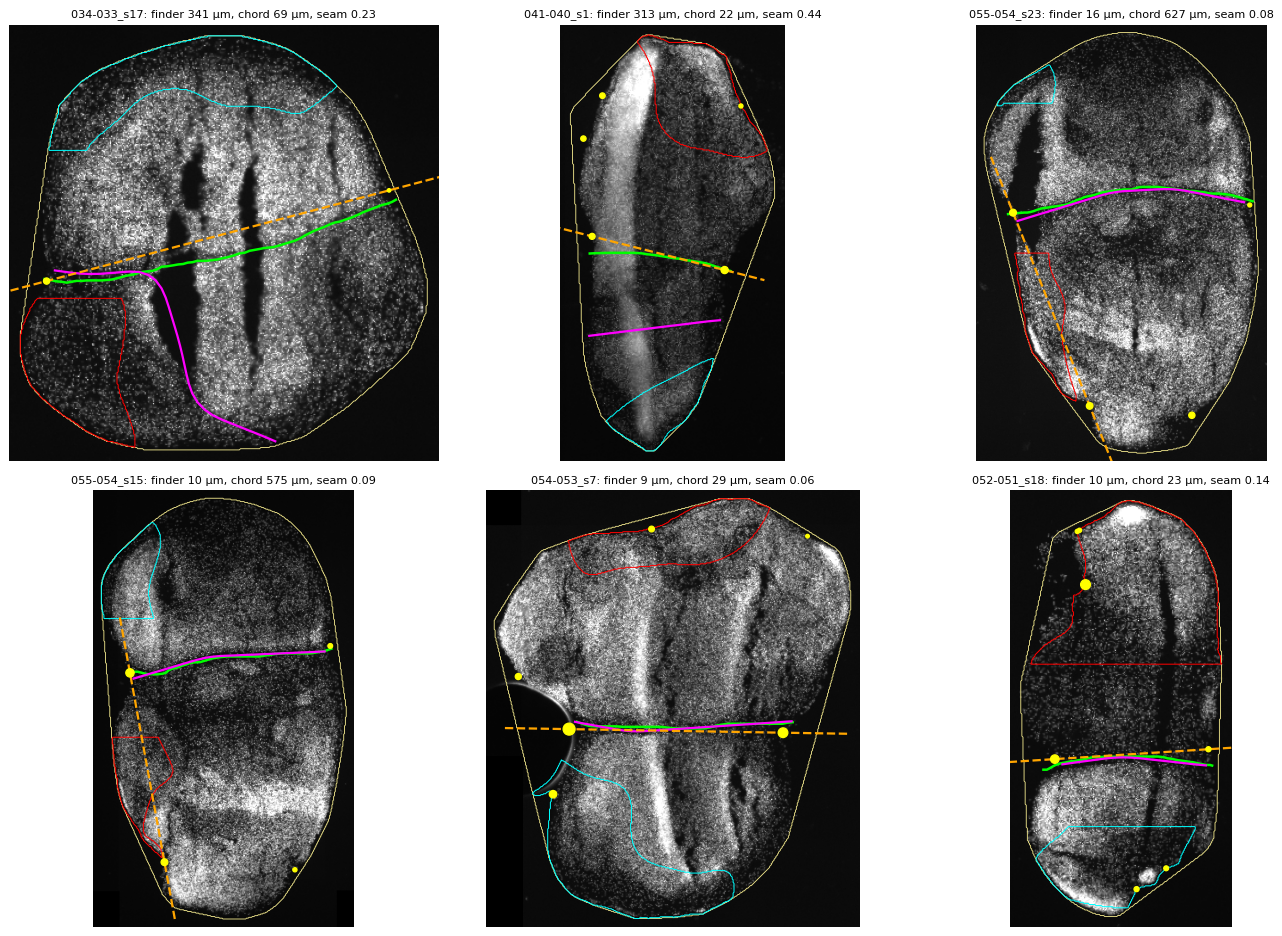

In [36]:
order_m = m.set_index("name")
show = (list(order_m[ERR["finder"]].nlargest(2).index)
        + list((order_m[ERR["notch chord"]] - order_m[ERR["finder"]]).nlargest(2).index)
        + list(order_m[ERR["finder"]].nsmallest(4).index))
show = list(dict.fromkeys(show))[:6]          # a sample can be in two of the groups
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for ax, name in zip(axes.ravel(), show):
    g = geo[name]
    um_ = g["um"]
    stain = g["stain"].astype(float)
    ax.imshow(stain, cmap="gray", vmax=np.percentile(stain[g["filled"]], 99))
    ax.contour(g["hull"], [0.5], colors="khaki", linewidths=0.7)
    ax.contour(g["seeds"][0], [0.5], colors="red", linewidths=0.8)
    ax.contour(g["seeds"][1], [0.5], colors="cyan", linewidths=0.8)
    pk = g["points"][g["peaks"]]
    ax.scatter(pk[:, 1], pk[:, 0], s=g["depth"][g["peaks"]] / 3, color="yellow", zorder=3)
    man = g["manual"] / um_
    ax.plot(man[:, 1], man[:, 0], color="lime", lw=2)
    for key, colour in (("finder", "magenta"), ("notch chord", "orange")):
        if key in g["lines"]:
            ln = g["lines"][key] / um_
            ax.plot(ln[:, 1], ln[:, 0], color=colour, lw=1.8, ls="-" if key == "finder" else "--")
    r = order_m.loc[name]
    ax.set_title(f"{name.split('_')[-2]}_{name.split('_')[-1]}: finder {r[ERR['finder']]:.0f} µm, "
                 f"chord {r[ERR['notch chord']]:.0f} µm, seam {r['seam price']:.2f}", fontsize=9)
    rows_, cols_ = np.nonzero(g["filled"])
    ax.set_xlim(cols_.min() - 10, cols_.max() + 10); ax.set_ylim(rows_.max() + 10, rows_.min() - 10)
    ax.set_axis_off()
fig.tight_layout()
plt.show()

### What it showed (22 October 2026, 29 samples with seeds)

- **The junction ends in notches.** Where the hand-drawn line meets the outline, the concavity is at a median 91st percentile of the outline, and 74 % of the ends are in the top quarter (p ≈ 6e-9 against a random place). The median distance along the outline to the nearest notch is 34 µm, against 417 µm for a random point. Both ends are in the top quarter in 17 of 29 samples. The finder's ends are in notches too (median 89th percentile): a minimum cut is already the shortest way across, which runs from notch to notch. So this is information the finder already uses.
- **Halfway between the seeds, roughly square across.** The hand-drawn junction sits at t = 0.51 ± 0.11 on the axis between the seed centres (range 0.30–0.75), at a median 82° to it. It moves with the share of tissue on the labelled side (Spearman 0.63) — the bigger the labelled organoid, the further from its seed — which is what an outline split at the junction should do. The finder sits at the same place (t 0.51).
- **The narrowest point is not the junction.** The narrowest width between the seeds is at t 0.67 on average, unrelated to the junction's position (Spearman 0.22, p 0.26). A straight line there is 316 µm off. A waist across the whole section is rarer than a pair of notches.
- **Shape alone is worse than the finder, except where the finder fails badly.** The notch chord is a median 85 µm off (finder 28 µm) and better than the finder on 6 of 26. Among those 6 are the finder's two worst failures: 041-040_s1 (313 → 22 µm) and 034-033_s17 (341 → 69 µm). On clean samples the chord often joins the wrong pair of notches (055-054_s15 and s23: 575 and 627 µm). The straight line halfway between the seeds is a median 138 µm off.
- **Shape does not predict the finder's failures.** Solidity, number and depth of notches, how narrow the waist is, seed distance, the junction's angle, the labelled share, and whether the finder's own line ends in notches are all weakly correlated with its error at best (|ρ| ≤ 0.36, none p < 0.05). Disagreement between the finder and the notch chord does not either (ρ 0.01). The seam price does (ρ 0.61, p < 0.001).
- **Use.** Notches are a strong prior for where a junction *ends*, but the finder already follows it. The chord rescues the worst two failures, but there is no way yet to tell when to trust it. The most promising use is in the no-seam fallback: end the cut at the deepest notches on either side of the seed axis instead of anywhere between dominant seeds. Like the fallback, that needs more hand-drawn no-seam sections to test.